# Phase 1 Complete Analysis — UCI Bank Marketing Full (`bank_marketing`)

**Source:** [UCI Machine Learning Repository (ID 222)](https://archive.ics.uci.edu/dataset/222/bank+marketing) / [Direct ZIP](https://archive.ics.uci.edu/static/public/222/bank+marketing.zip)  
**Domain & Goal:** Portuguese bank telemarketing campaign dataset (`41,188` raw rows × `21` columns, `;`-delimited; target: term-deposit subscription `y` [`yes`/`no`]). Key challenges include `12,718` `'unknown'` missing-value placeholders across 6 columns, sentinel code `pdays = 999`, collinear macroeconomic indicators, and `11.27%` minority class imbalance.

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "bank_marketing"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: bank_marketing | Raw shape: 41,188 rows x 21 cols | Exact duplicates: 12


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
age,int64,numeric_continuous,0.0%,78,"numeric values (100.0% parseable, 78 unique)"
job,object,categorical_nominal,0.8%,11,string categorical with 11 normalized unique values (raw=11)
marital,object,categorical_nominal,0.19%,3,string categorical with 3 normalized unique values (raw=3)
education,object,categorical_nominal,4.2%,7,string categorical with 7 normalized unique values (raw=7)
default,object,binary,20.87%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['no', 'yes'])"
housing,object,binary,2.4%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['no', 'yes'])"
loan,object,binary,2.4%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['no', 'yes'])"
contact,object,binary,0.0%,2,"string column with 2 distinct normalized values ('cellular', 'telephone')"
month,object,categorical_nominal,0.0%,10,string categorical with 10 normalized unique values (raw=10)
day_of_week,object,categorical_nominal,0.0%,5,string categorical with 5 normalized unique values (raw=5)


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `bank_marketing`

## Summary
4 cleaning step group(s) recorded; 0 column(s) type-converted; 12718 cell(s) normalized (whitespace/missing tokens/categories); 12 duplicate row(s) removed; 0 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `normalize_missing_tokens` | `job` | `converted_to_NaN` | info | 330 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 330) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `normalize_missing_tokens` | `marital` | `converted_to_NaN` | info | 80 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 80) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `normalize_missing_tokens` | `education` | `converted_to_NaN` | info | 1731 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 1731) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `normalize_missing_tokens` | `default` | `converted_to_NaN` | warning | 8597 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 8597) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `normalize_missing_tokens` | `housing` | `converted_to_NaN` | info | 990 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 990) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `normalize_missing_tokens` | `loan` | `converted_to_NaN` | info | 990 | 41188 -> 41188 | Replaced placeholder missing token(s) ('unknown': 990) with NaN. | `unknown` -> `NaN`; `unknown` -> `NaN`; `unknown` -> `NaN` |
| `handle_duplicates` | *(table)* | `dropped_duplicate_rows` | info | 252 | 41188 -> 41176 | Dropped 12 exact duplicate row(s) (kept first occurrence). | - |
| `handle_missing_values` | `job` | `imputed_mode` | info | 330 | 41176 -> 41176 | Imputed 330 missing cell(s) (0.8%) in 'job' with mode='admin.' (imputed output only). | `NaN` -> `admin.`; `NaN` -> `admin.`; `NaN` -> `admin.` |
| `handle_missing_values` | `marital` | `imputed_mode` | info | 80 | 41176 -> 41176 | Imputed 80 missing cell(s) (0.2%) in 'marital' with mode='married' (imputed output only). | `NaN` -> `married`; `NaN` -> `married`; `NaN` -> `married` |
| `handle_missing_values` | `education` | `imputed_mode` | info | 1730 | 41176 -> 41176 | Imputed 1730 missing cell(s) (4.2%) in 'education' with mode='university.degree' (imputed output only). | `NaN` -> `university.degree`; `NaN` -> `university.degree`; `NaN` -> `university.degree` |
| `handle_missing_values` | `default` | `imputed_missing_level` | info | 8596 | 41176 -> 41176 | Imputed 8596 missing cell(s) (20.9%) in 'default' with missing_level='Missing' (imputed output only). | `NaN` -> `Missing`; `NaN` -> `Missing`; `NaN` -> `Missing` |
| `handle_missing_values` | `housing` | `imputed_mode` | info | 990 | 41176 -> 41176 | Imputed 990 missing cell(s) (2.4%) in 'housing' with mode='yes' (imputed output only). | `NaN` -> `yes`; `NaN` -> `yes`; `NaN` -> `yes` |
| `handle_missing_values` | `loan` | `imputed_mode` | info | 990 | 41176 -> 41176 | Imputed 990 missing cell(s) (2.4%) in 'loan' with mode='no' (imputed output only). | `NaN` -> `no`; `NaN` -> `no`; `NaN` -> `no` |
| `handle_outliers` | `age` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 468 outlier(s) (1.1%) and 4 extreme outlier(s) in 'age' (action=flag; values untouched). | `70` -> `70`; `76` -> `76`; `73` -> `73` |
| `handle_outliers` | `duration` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 2963 outlier(s) (7.2%) and 1043 extreme outlier(s) in 'duration' (action=flag; values untouched). | `1666` -> `1666`; `787` -> `787`; `812` -> `812` |
| `handle_outliers` | `campaign` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 2406 outlier(s) (5.8%) and 1094 extreme outlier(s) in 'campaign' (action=flag; values untouched). | `7` -> `7`; `8` -> `8`; `8` -> `8` |
| `handle_outliers` | `pdays` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 1515 outlier(s) (3.7%) and 0 extreme outlier(s) in 'pdays' (action=flag; values untouched). | `6` -> `6`; `4` -> `4`; `4` -> `4` |
| `handle_outliers` | `previous` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 5625 outlier(s) (13.7%) and 0 extreme outlier(s) in 'previous' (action=flag; values untouched). | `1` -> `1`; `1` -> `1`; `1` -> `1` |
| `handle_outliers` | `emp.var.rate` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 13494 outlier(s) (32.8%) and 0 extreme outlier(s) in 'emp.var.rate' (action=flag; values untouched). | `-1.8` -> `-1.8`; `-1.8` -> `-1.8`; `-1.8` -> `-1.8` |
| `handle_outliers` | `cons.conf.idx` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 446 outlier(s) (1.1%) and 0 extreme outlier(s) in 'cons.conf.idx' (action=flag; values untouched). | `-26.9` -> `-26.9`; `-26.9` -> `-26.9`; `-26.9` -> `-26.9` |
| `handle_outliers` | `euribor3m` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 17081 outlier(s) (41.5%) and 0 extreme outlier(s) in 'euribor3m' (action=flag; values untouched). | `4.286` -> `4.286`; `4.286` -> `4.286`; `4.286` -> `4.286` |
| `handle_outliers` | `nr.employed` | `flagged_outliers` | info | 0 | 41176 -> 41176 | Flagged 1408 outlier(s) (3.4%) and 0 extreme outlier(s) in 'nr.employed' (action=flag; values untouched). | `4991.6` -> `4991.6`; `4991.6` -> `4991.6`; `4991.6` -> `4991.6` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (41176, 21) | Imputed cleaned shape: (41176, 22)


age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261.0,1.0,999.0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
57.0,services,married,high.school,NaN,no,no,telephone,may,mon,149.0,1.0,999.0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
37.0,services,married,high.school,no,yes,no,telephone,may,mon,226.0,1.0,999.0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,151.0,1.0,999.0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
56.0,services,married,high.school,no,no,yes,telephone,may,mon,307.0,1.0,999.0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 21 columns; the most common type is numeric_continuous (9 columns)
*Figure 1. 21 columns; the most common type is numeric_continuous (9 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


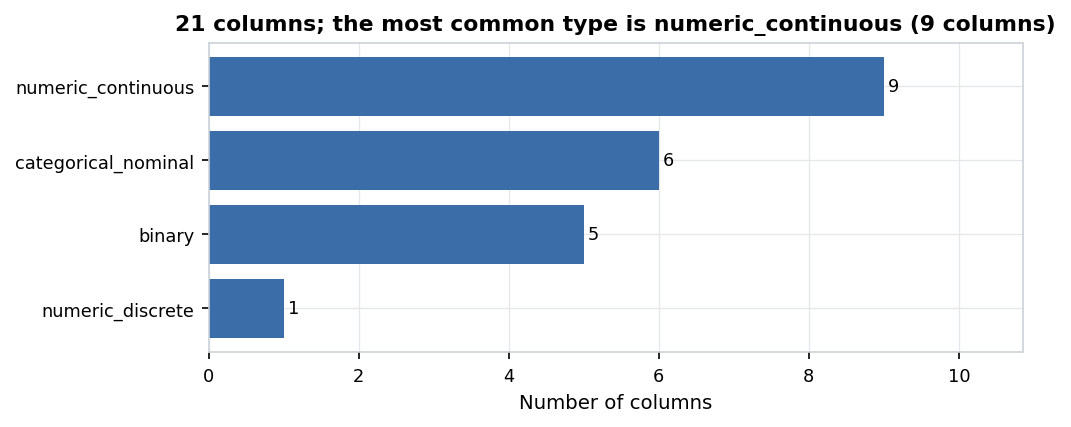

#### 6 of 21 columns have missing values; most is 'default' (20.9%)
*Figure 2. 6 of 21 columns have missing values; most is 'default' (20.9%).* Percent of rows missing per column (only columns with at least one gap). Red bars are above 40%.


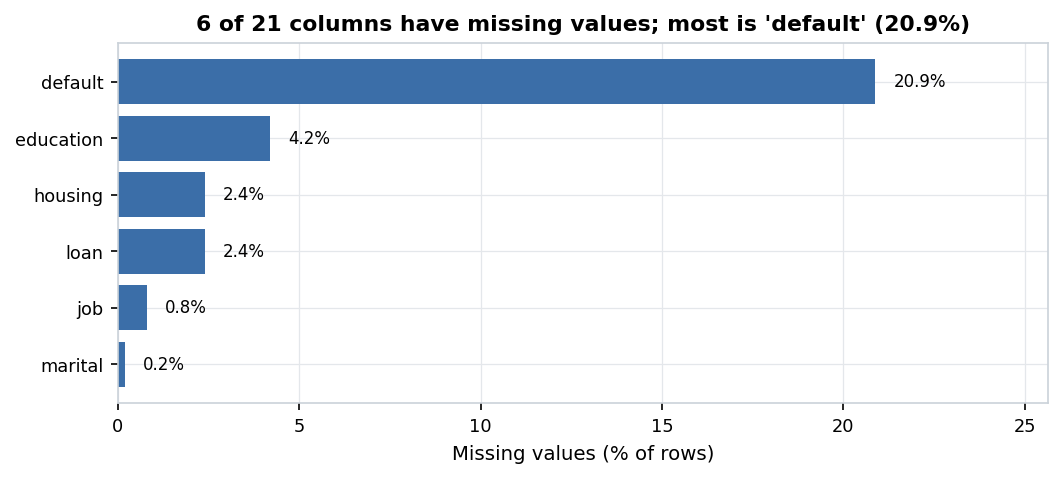

#### Missing values are spread out: the 10% of rows with the most gaps hold 48.25% of all missing cells
*Figure 3. Missing values are spread out: the 10% of rows with the most gaps hold 48.25% of all missing cells.* Each red cell is a missing value; rows are sorted by how many gaps they have. A random sample of 500 of 41,176 rows is shown.


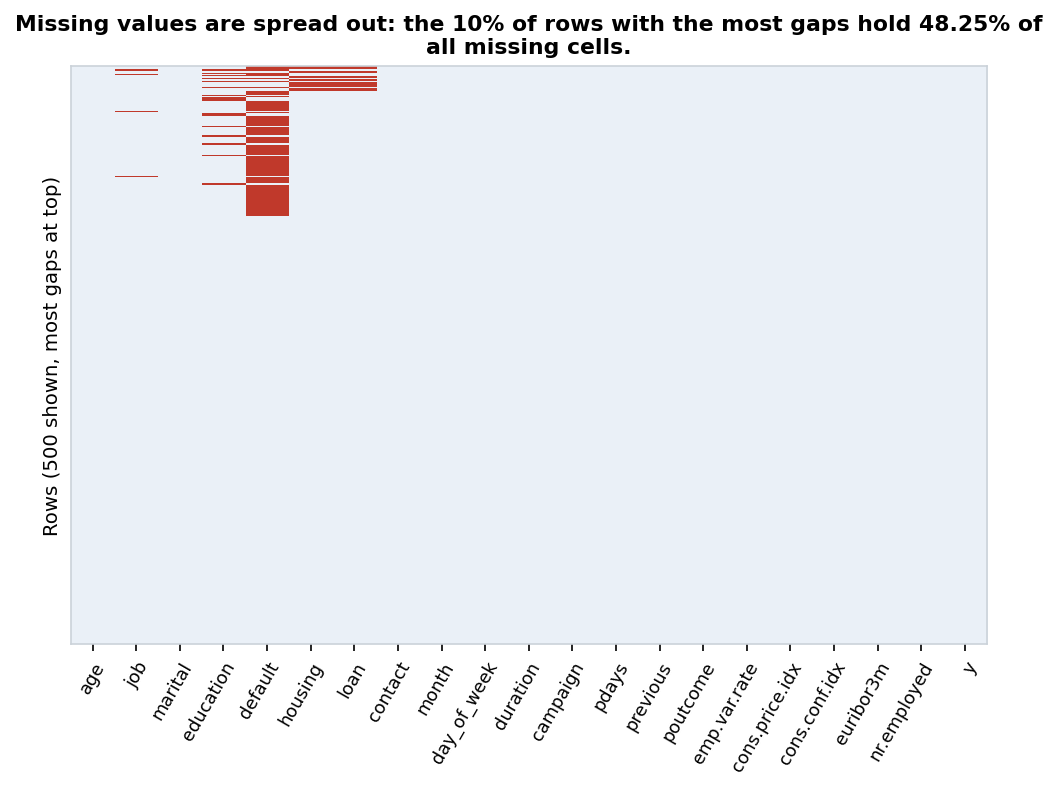

#### Missingness in 'housing' and 'loan' moves together most (r = +1.00)
*Figure 4. Missingness in 'housing' and 'loan' moves together most (r = +1.00).* Correlation between the missing/not-missing patterns of columns with gaps. High values mean the gaps tend to occur in the same rows. Descriptive only.


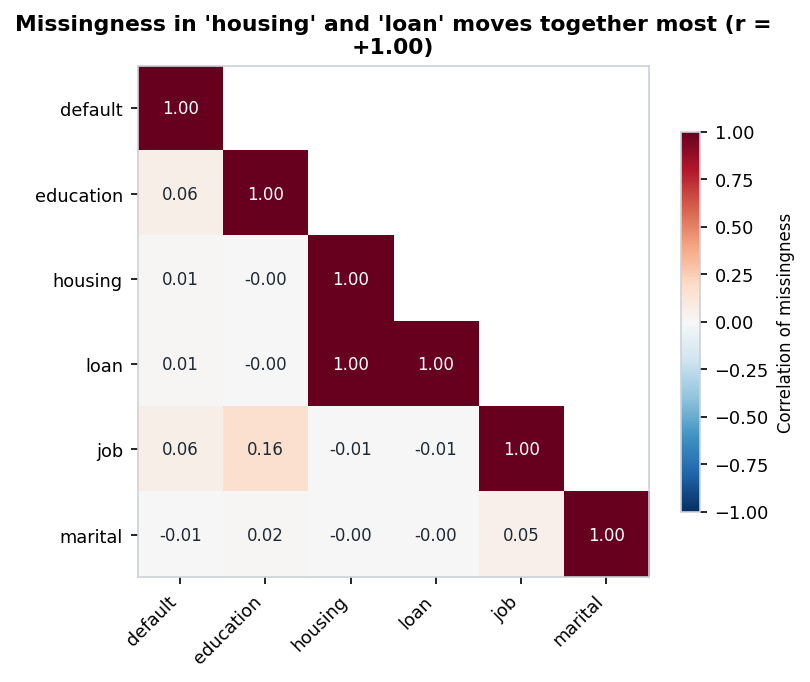

#### Numeric distributions (1/2): most skewed here is 'pdays' (skew -4.92)
*Figure 5. Numeric distributions (1/2): most skewed here is 'pdays' (skew -4.92).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


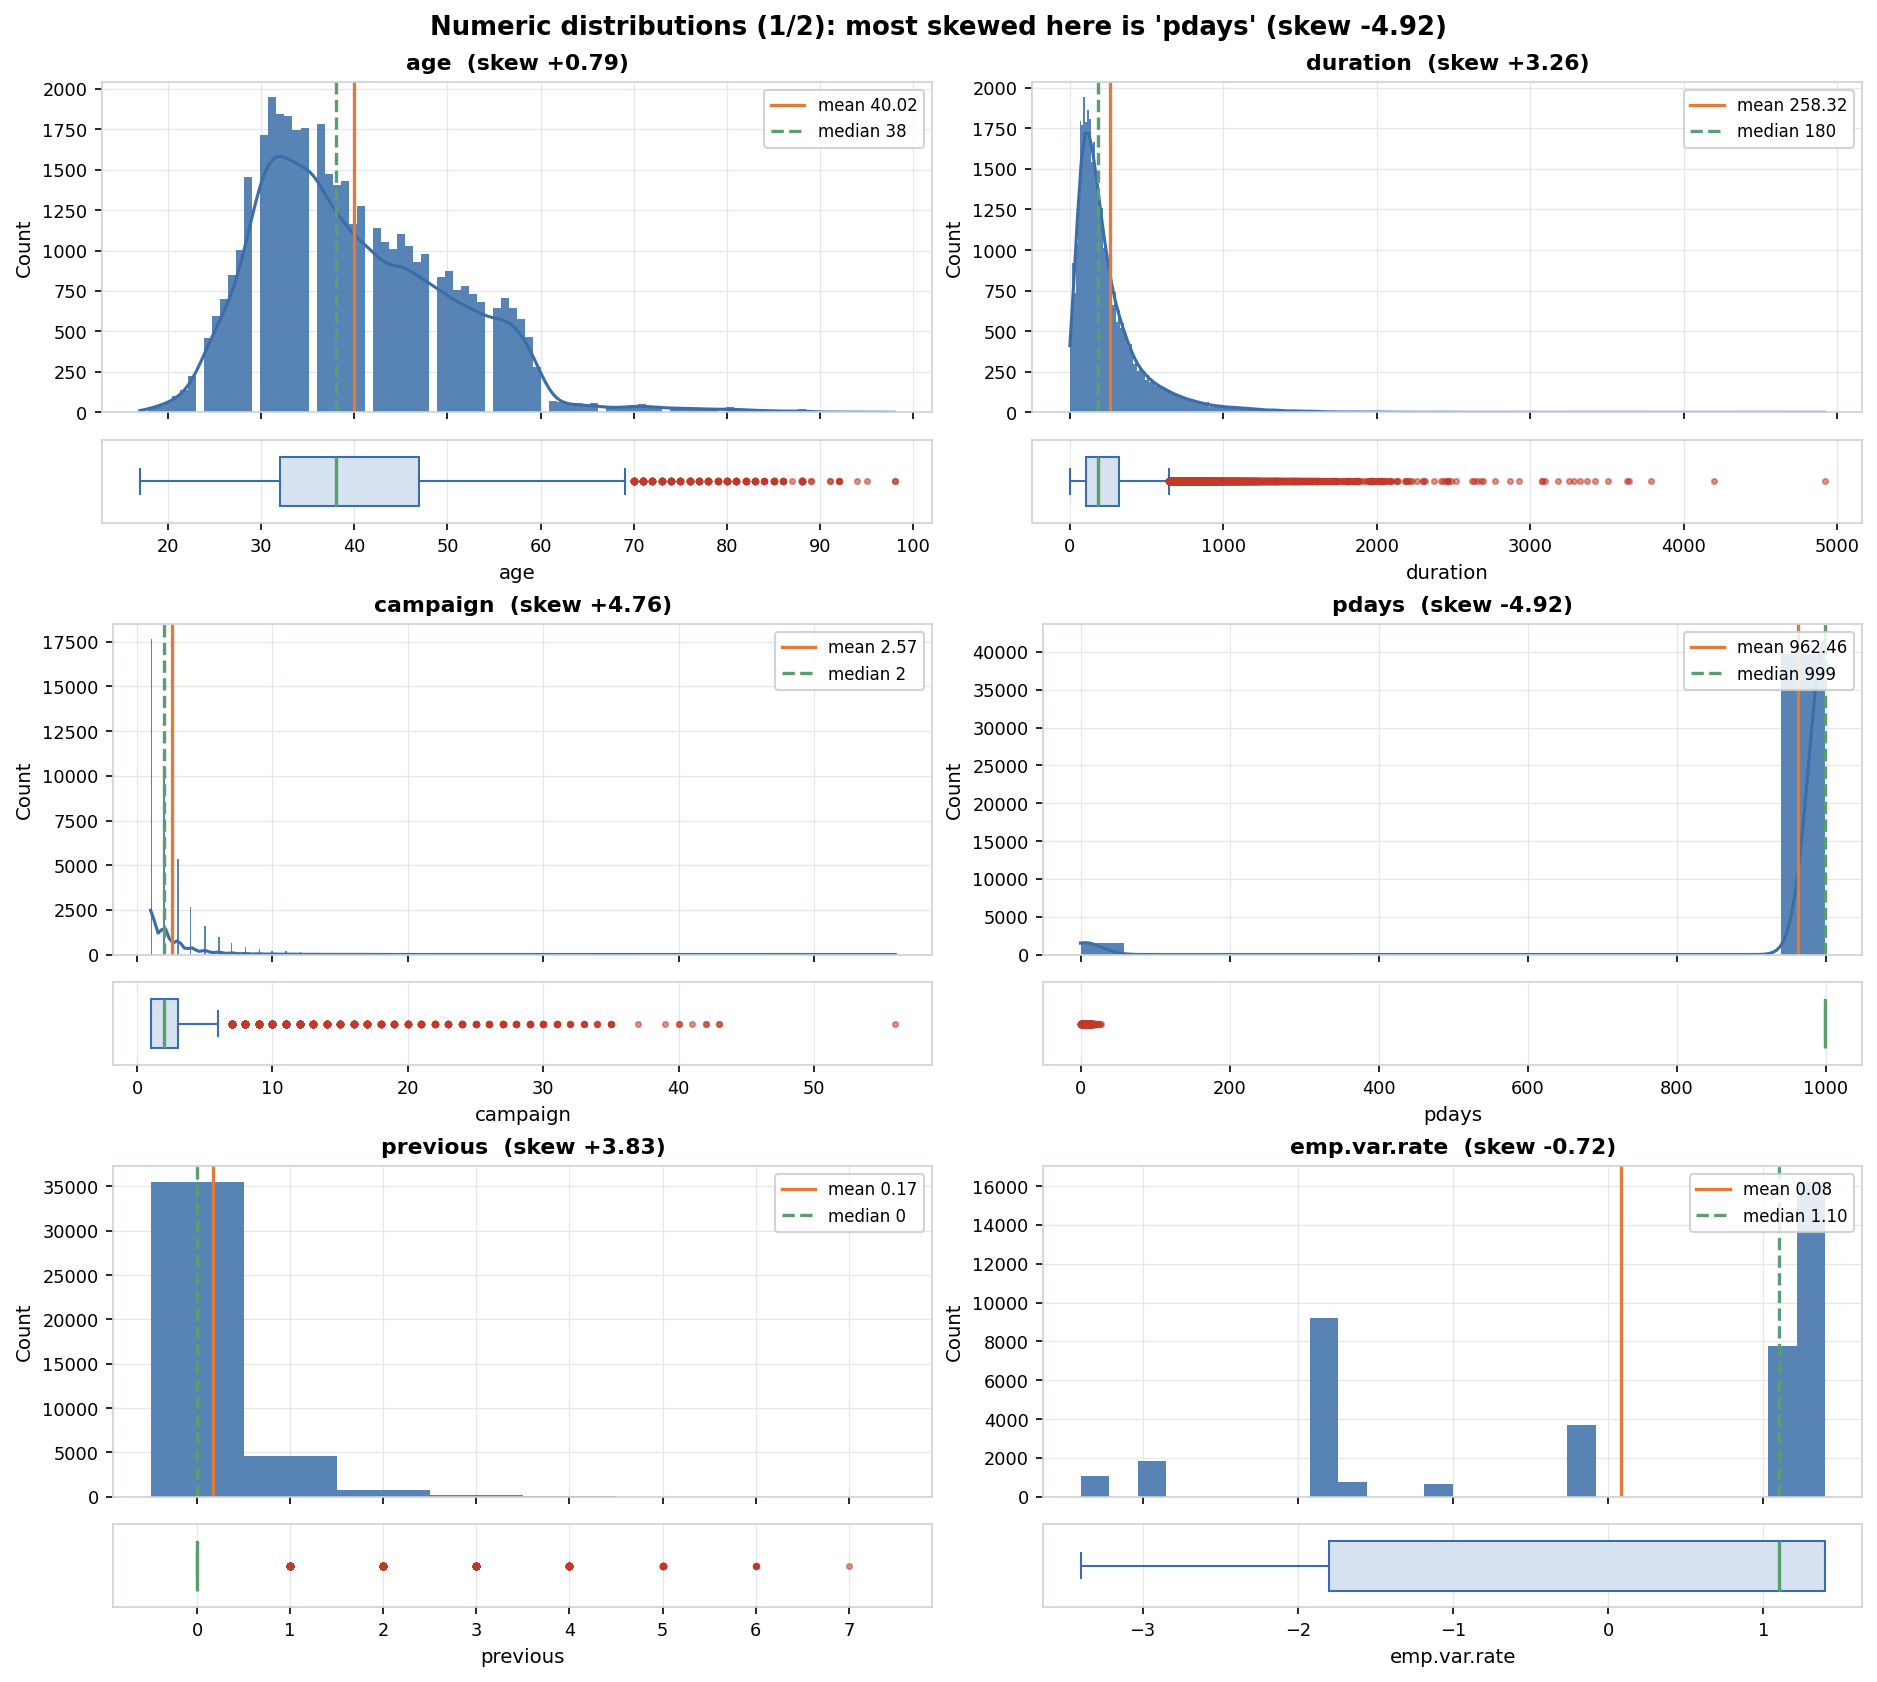

#### Numeric distributions (2/2): most skewed here is 'nr.employed' (skew -1.04)
*Figure 6. Numeric distributions (2/2): most skewed here is 'nr.employed' (skew -1.04).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


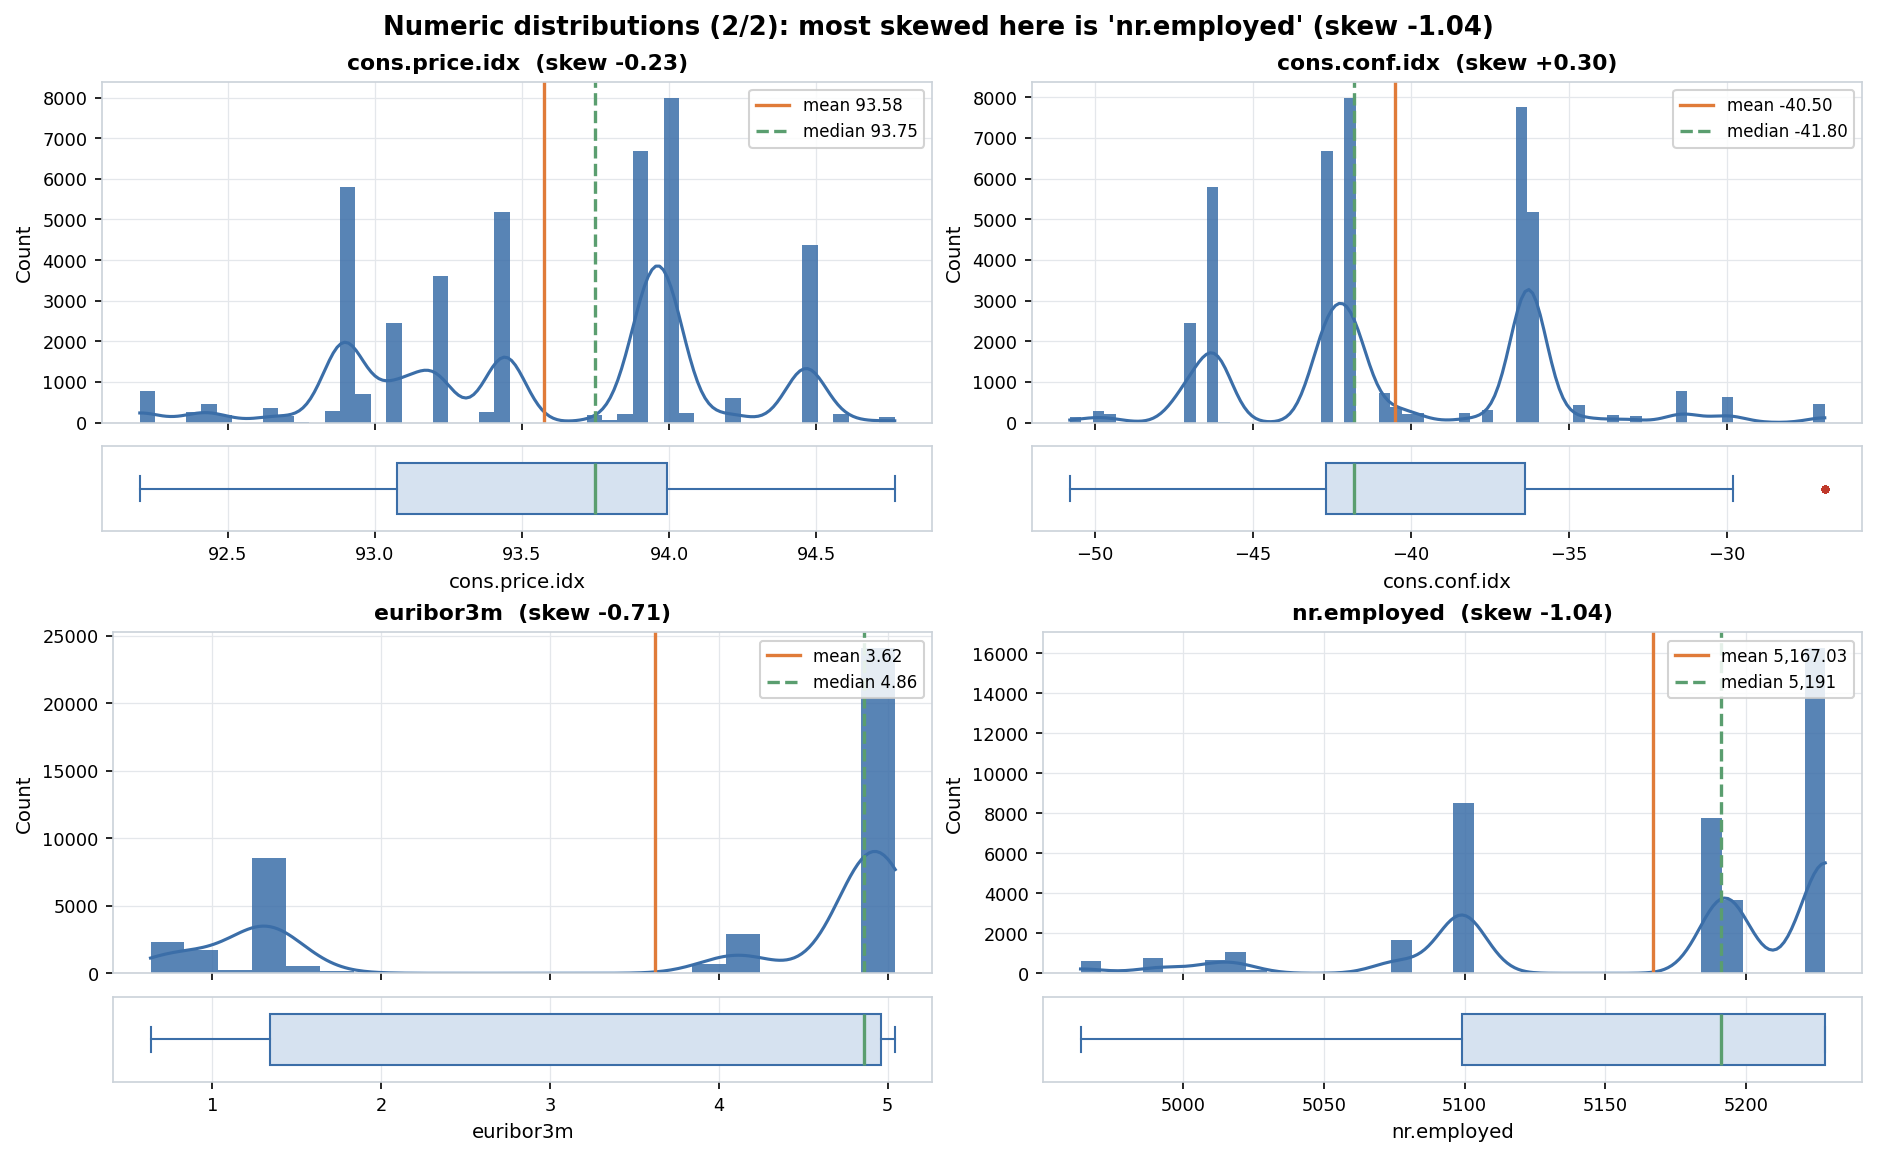

#### 'pdays' is left-skewed (skew -4.92)
*Figure 7. 'pdays' is left-skewed (skew -4.92).* Close-up of a skewed or outlier-heavy column.


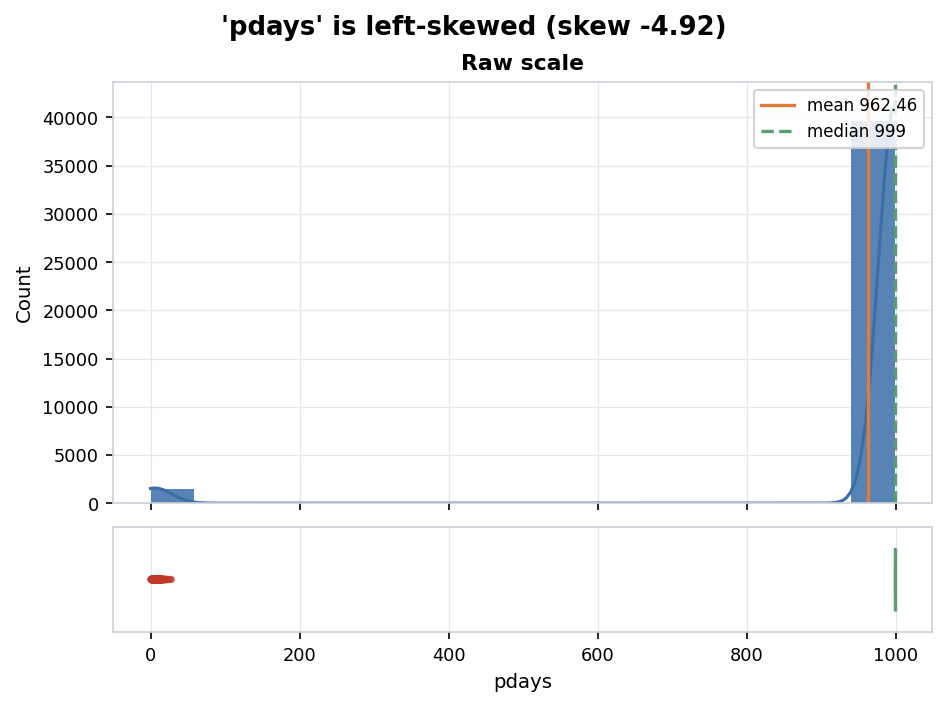

#### 'campaign' is right-skewed (skew +4.76) and has 5.8% IQR outliers
*Figure 8. 'campaign' is right-skewed (skew +4.76) and has 5.8% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


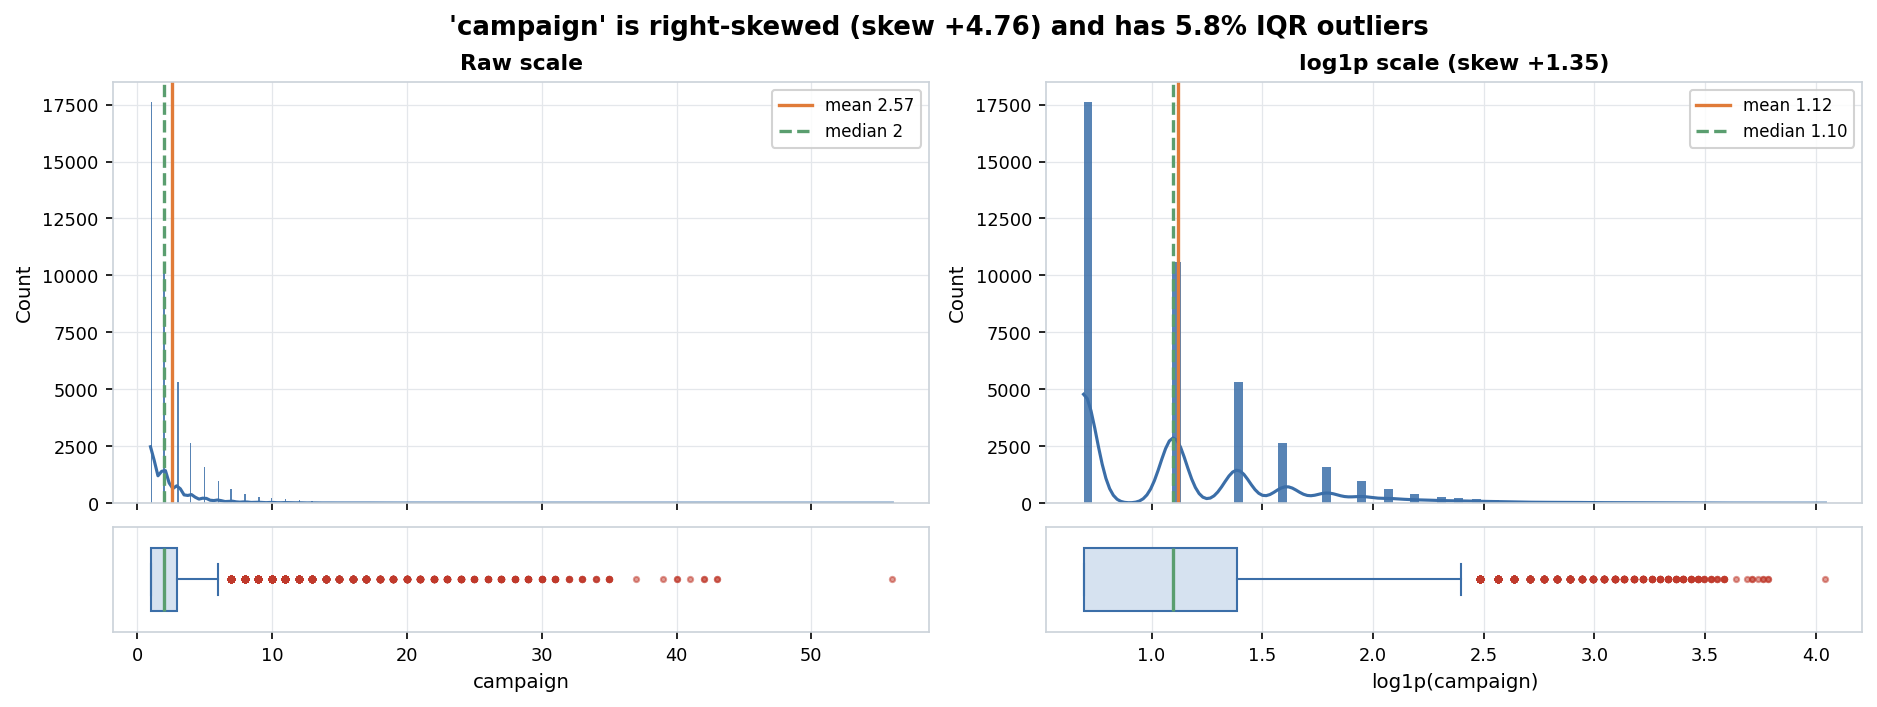

#### 'previous' is right-skewed (skew +3.83) and has 13.7% IQR outliers
*Figure 9. 'previous' is right-skewed (skew +3.83) and has 13.7% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


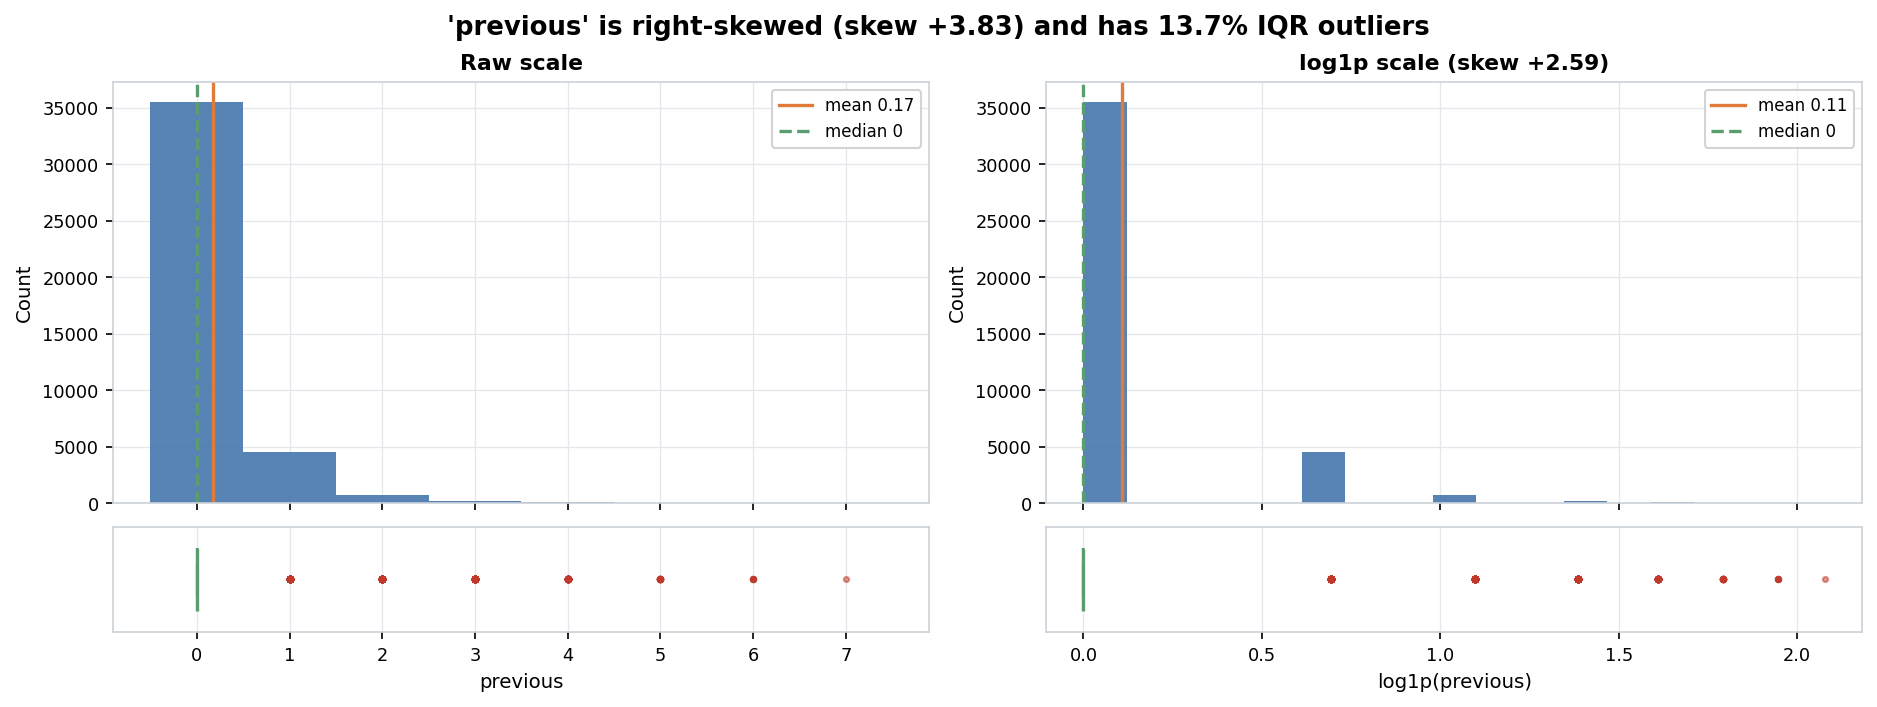

#### 'duration' is right-skewed (skew +3.26) and has 7.2% IQR outliers
*Figure 10. 'duration' is right-skewed (skew +3.26) and has 7.2% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


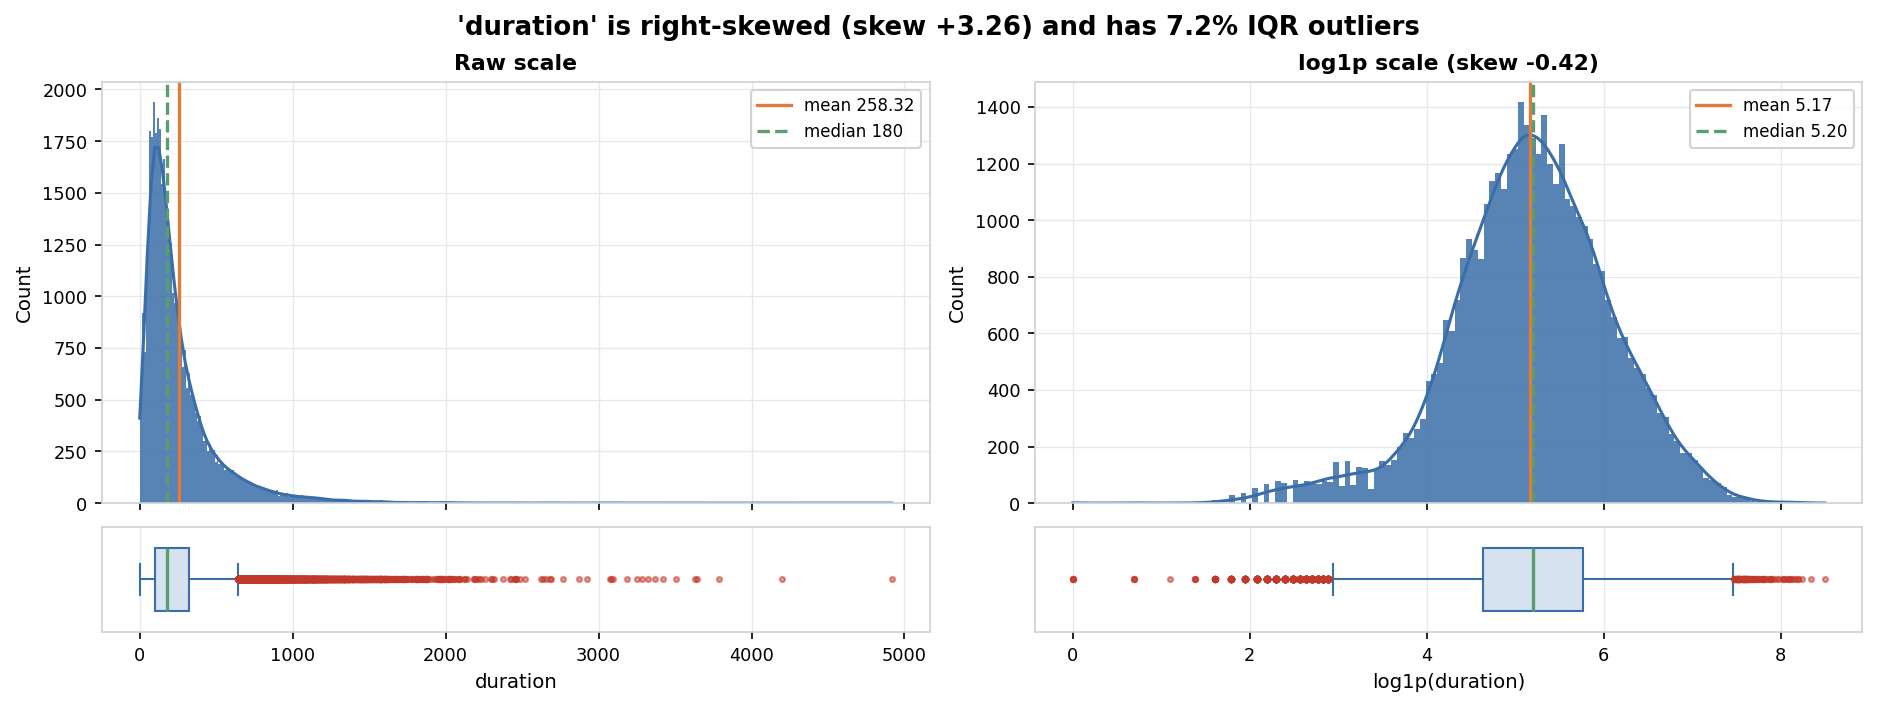

#### 'nr.employed' is left-skewed (skew -1.04)
*Figure 11. 'nr.employed' is left-skewed (skew -1.04).* Close-up of a skewed or outlier-heavy column.


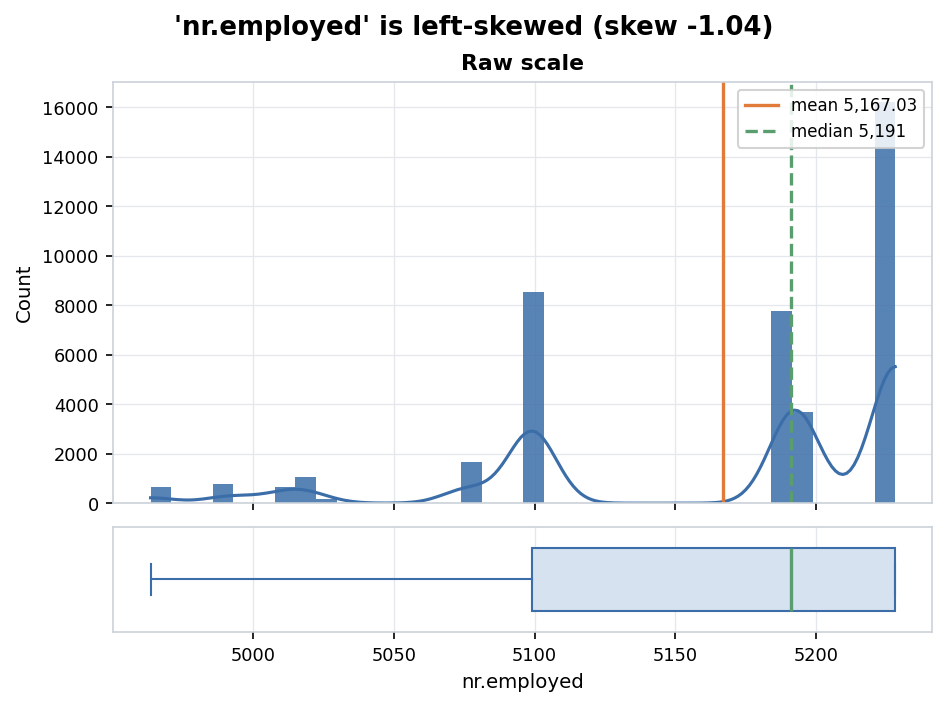

#### 'previous' has the most IQR outliers (13.7% of its values)
*Figure 12. 'previous' has the most IQR outliers (13.7% of its values).* Share of each numeric column's values outside 1.5×IQR. Outliers are only flagged, not removed, in the conservative cleaned data. Red bars are above the guide line.


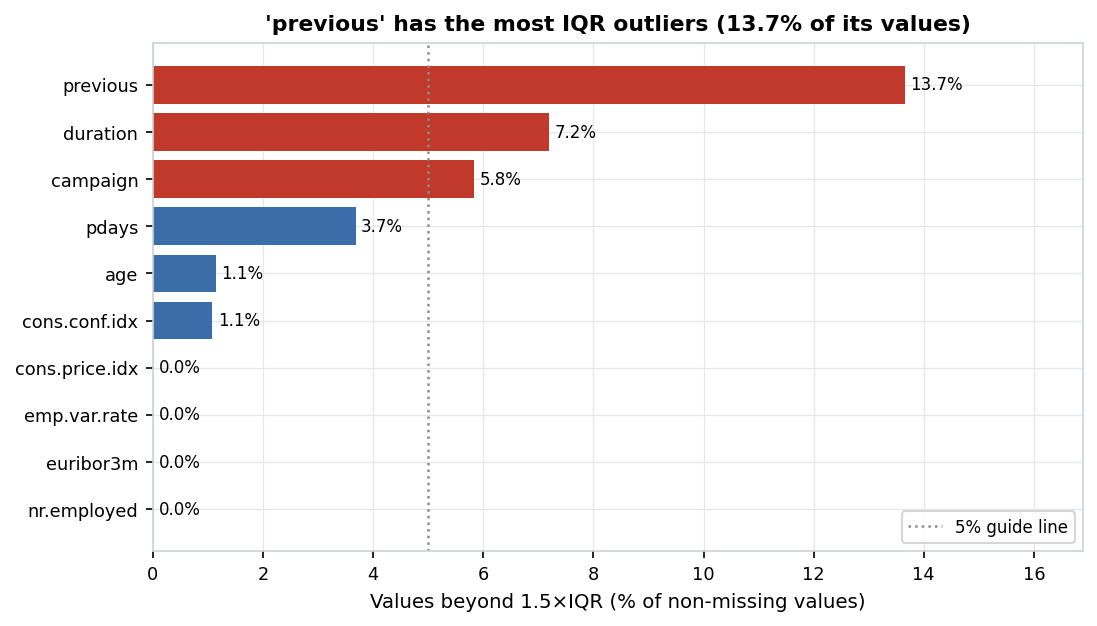

#### Categorical distributions (1/2): most lopsided here is 'default' (top level 99.99%)
*Figure 13. Categorical distributions (1/2): most lopsided here is 'default' (top level 99.99%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


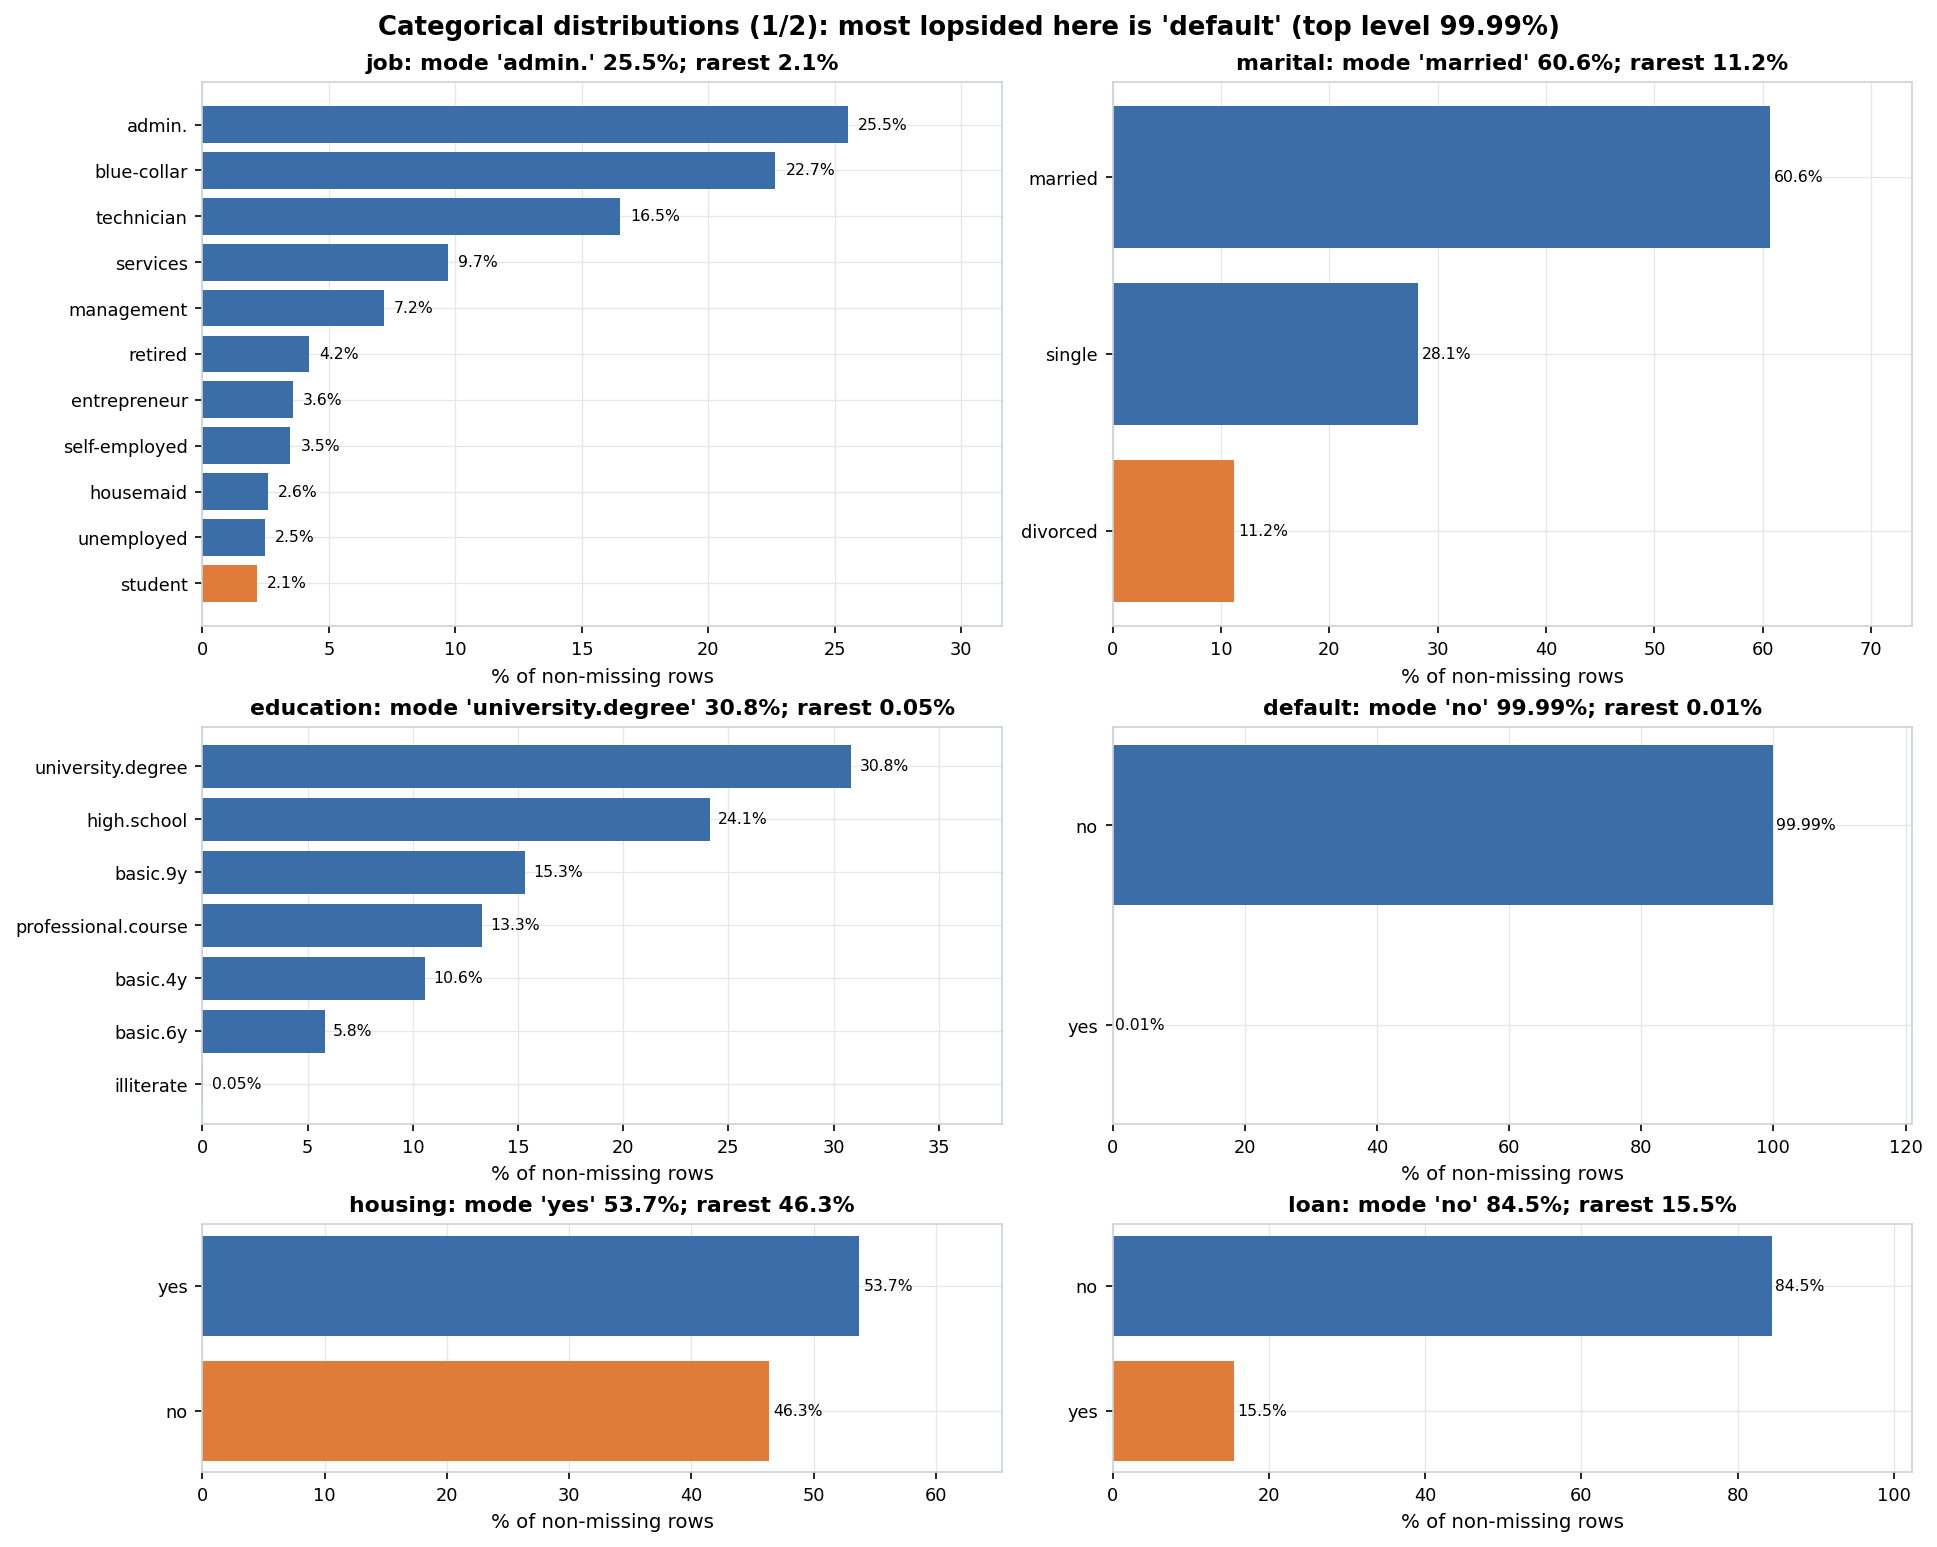

#### Categorical distributions (2/2): most lopsided here is 'y' (top level 88.7%)
*Figure 14. Categorical distributions (2/2): most lopsided here is 'y' (top level 88.7%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


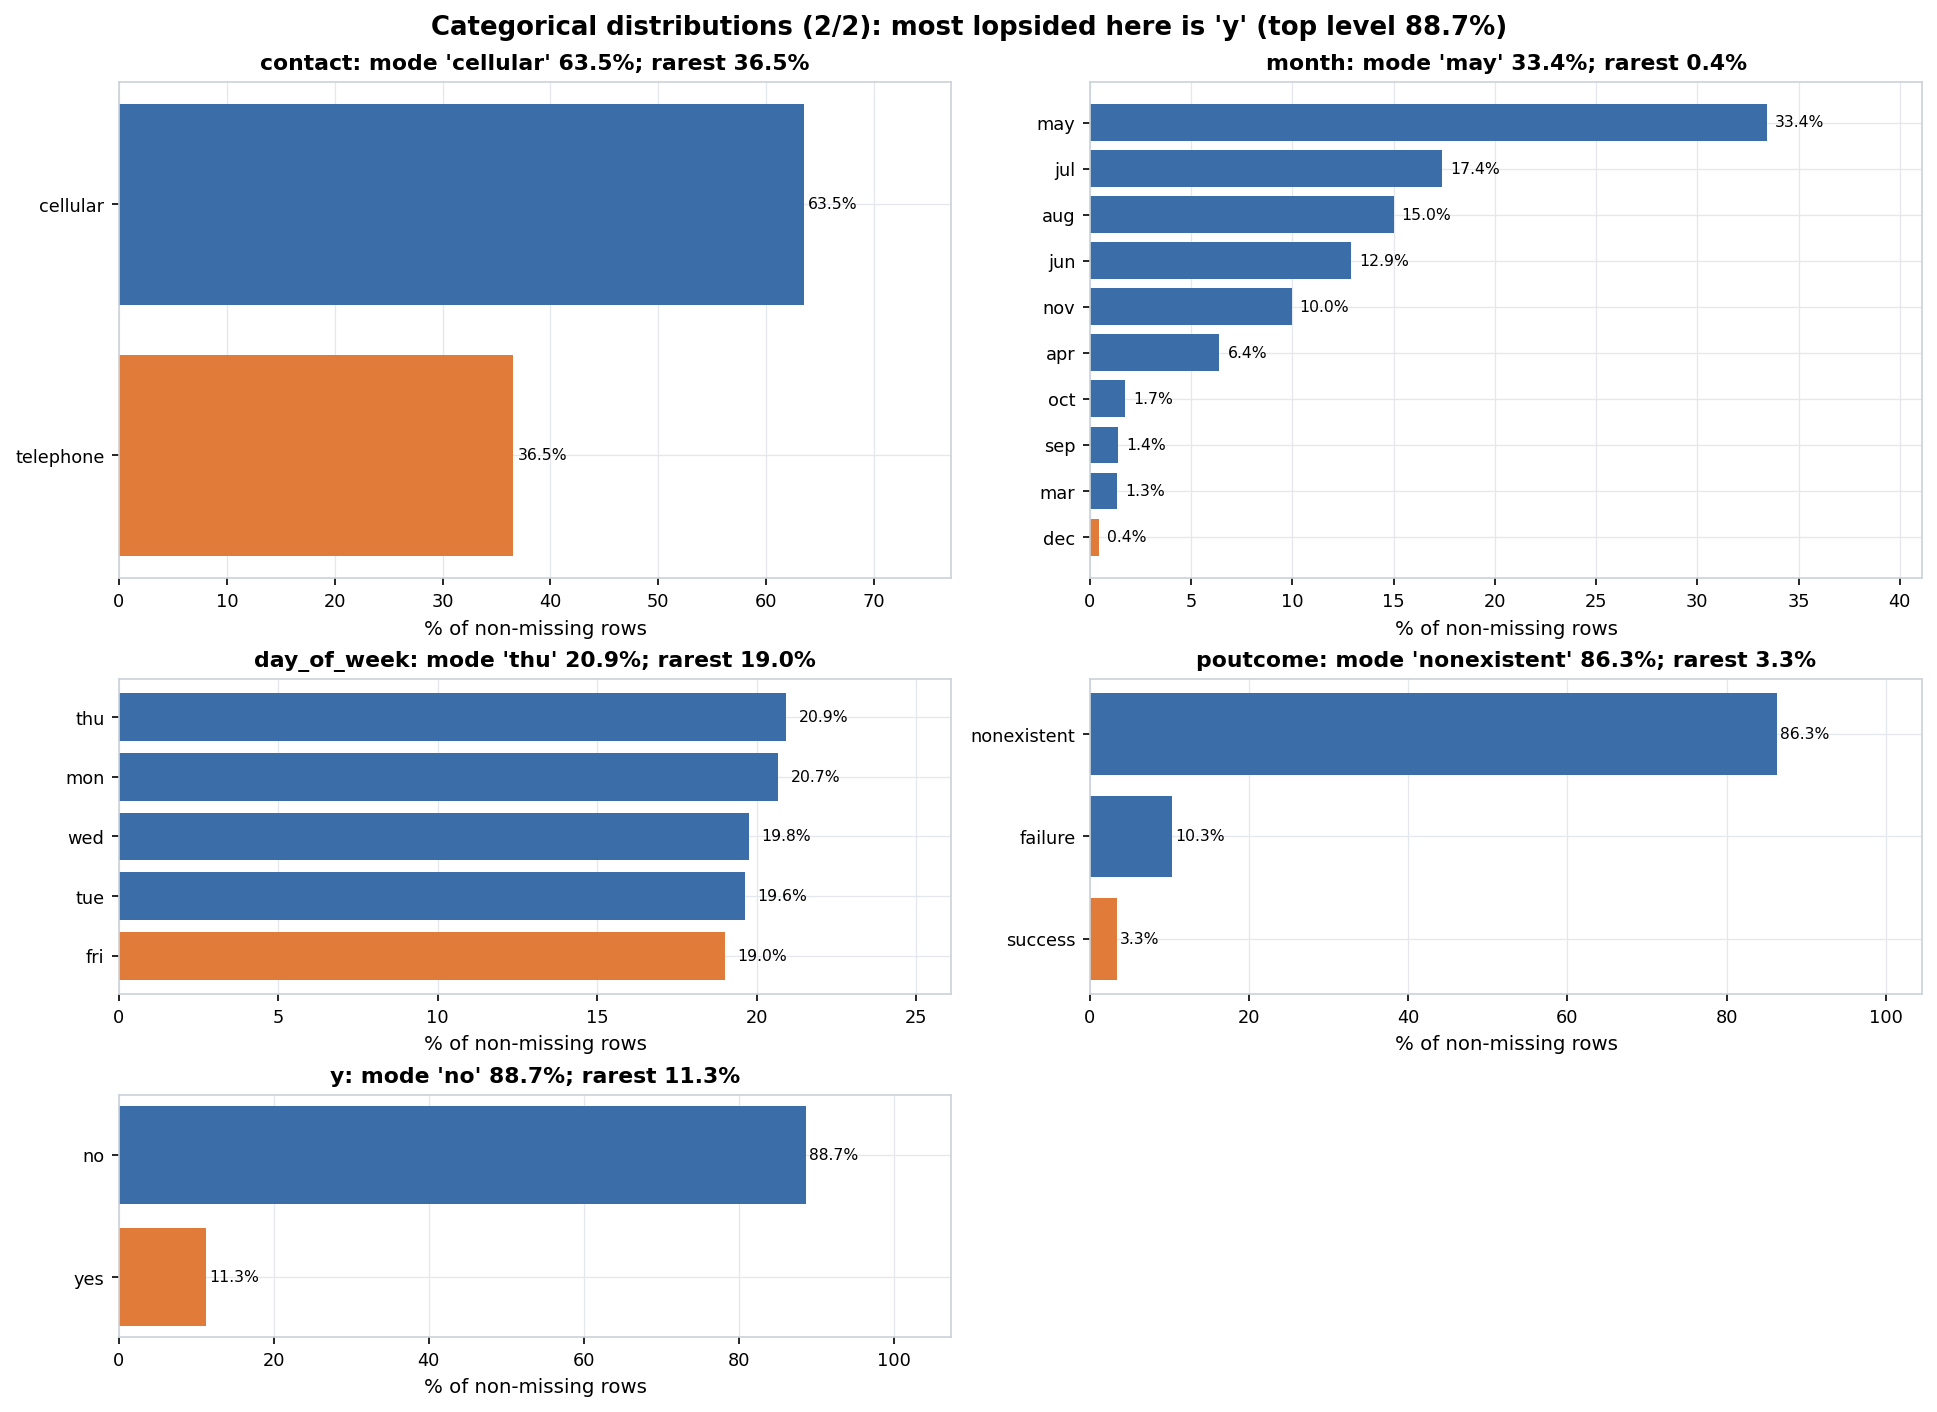

#### 'job' has the most levels (11)
*Figure 15. 'job' has the most levels (11).* Number of distinct values in each categorical or binary column.


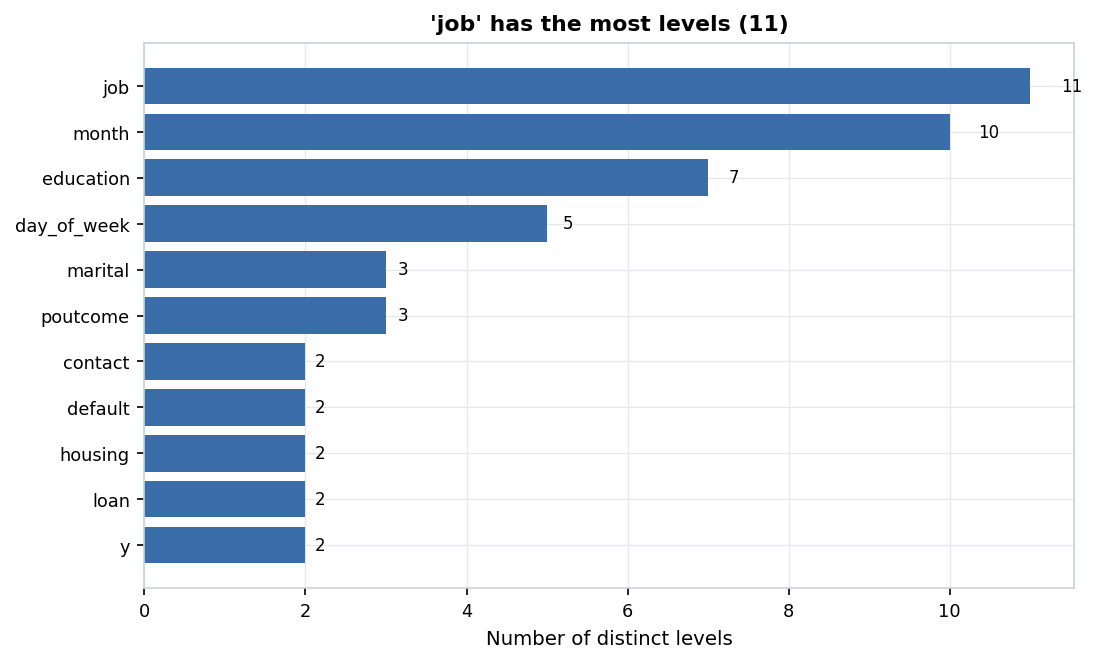

#### Target 'y' is mildly imbalanced: smallest class 'yes' is 11.3% of rows (ratio 7.88:1)
*Figure 16. Target 'y' is mildly imbalanced: smallest class 'yes' is 11.3% of rows (ratio 7.88:1).* Rows per target class. The orange bar is the smallest class. Highly imbalanced = smallest class under 10% of rows; mildly = largest/smallest ratio of 1.5 or more.


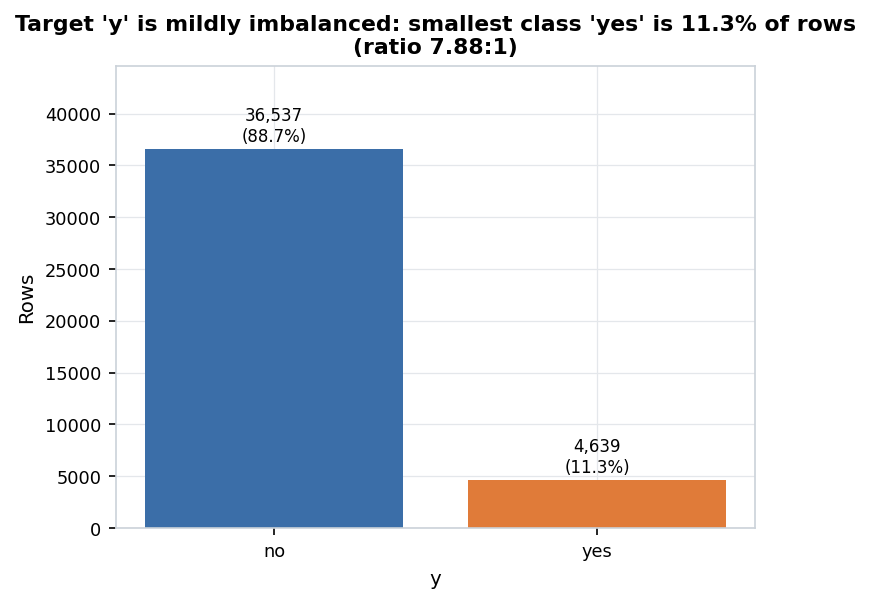

#### The 'y' mix changes most across levels of 'poutcome' (Cramér's V 0.32)
*Figure 17. The 'y' mix changes most across levels of 'poutcome' (Cramér's V 0.32).* Share of each target class within each level of the categorical features most associated with the target (bias-corrected Cramér's V). Descriptive coefficients only; no hypothesis tests were run.


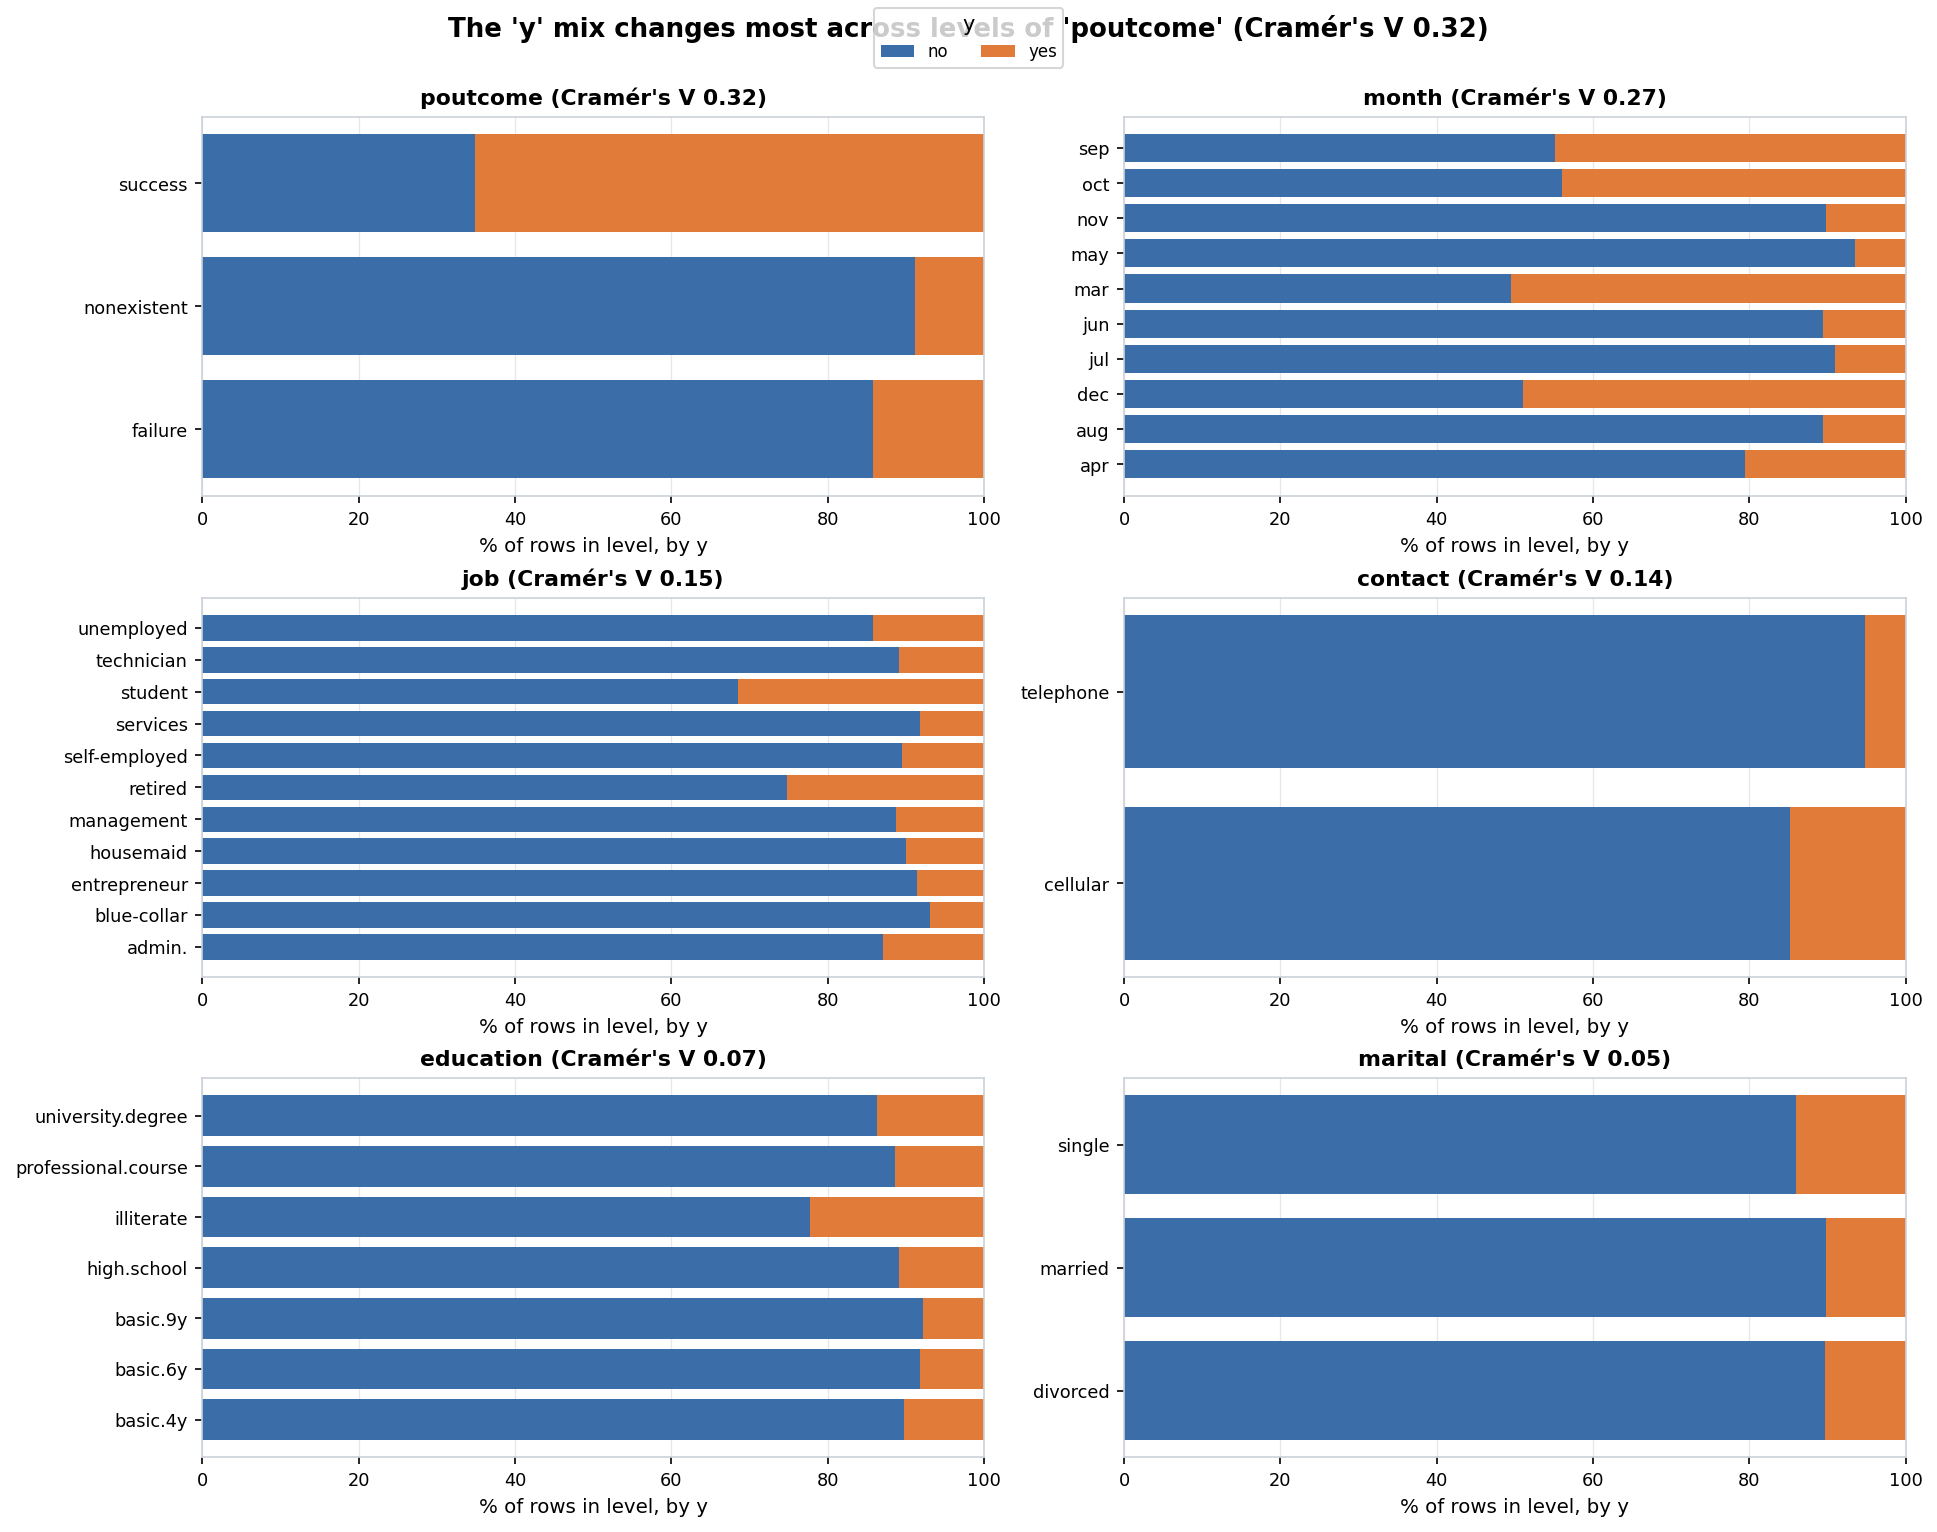

#### Strongest numeric pair: 'emp.var.rate' vs 'nr.employed' (Spearman +0.94, Pearson +0.91)
*Figure 18. Strongest numeric pair: 'emp.var.rate' vs 'nr.employed' (Spearman +0.94, Pearson +0.91).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


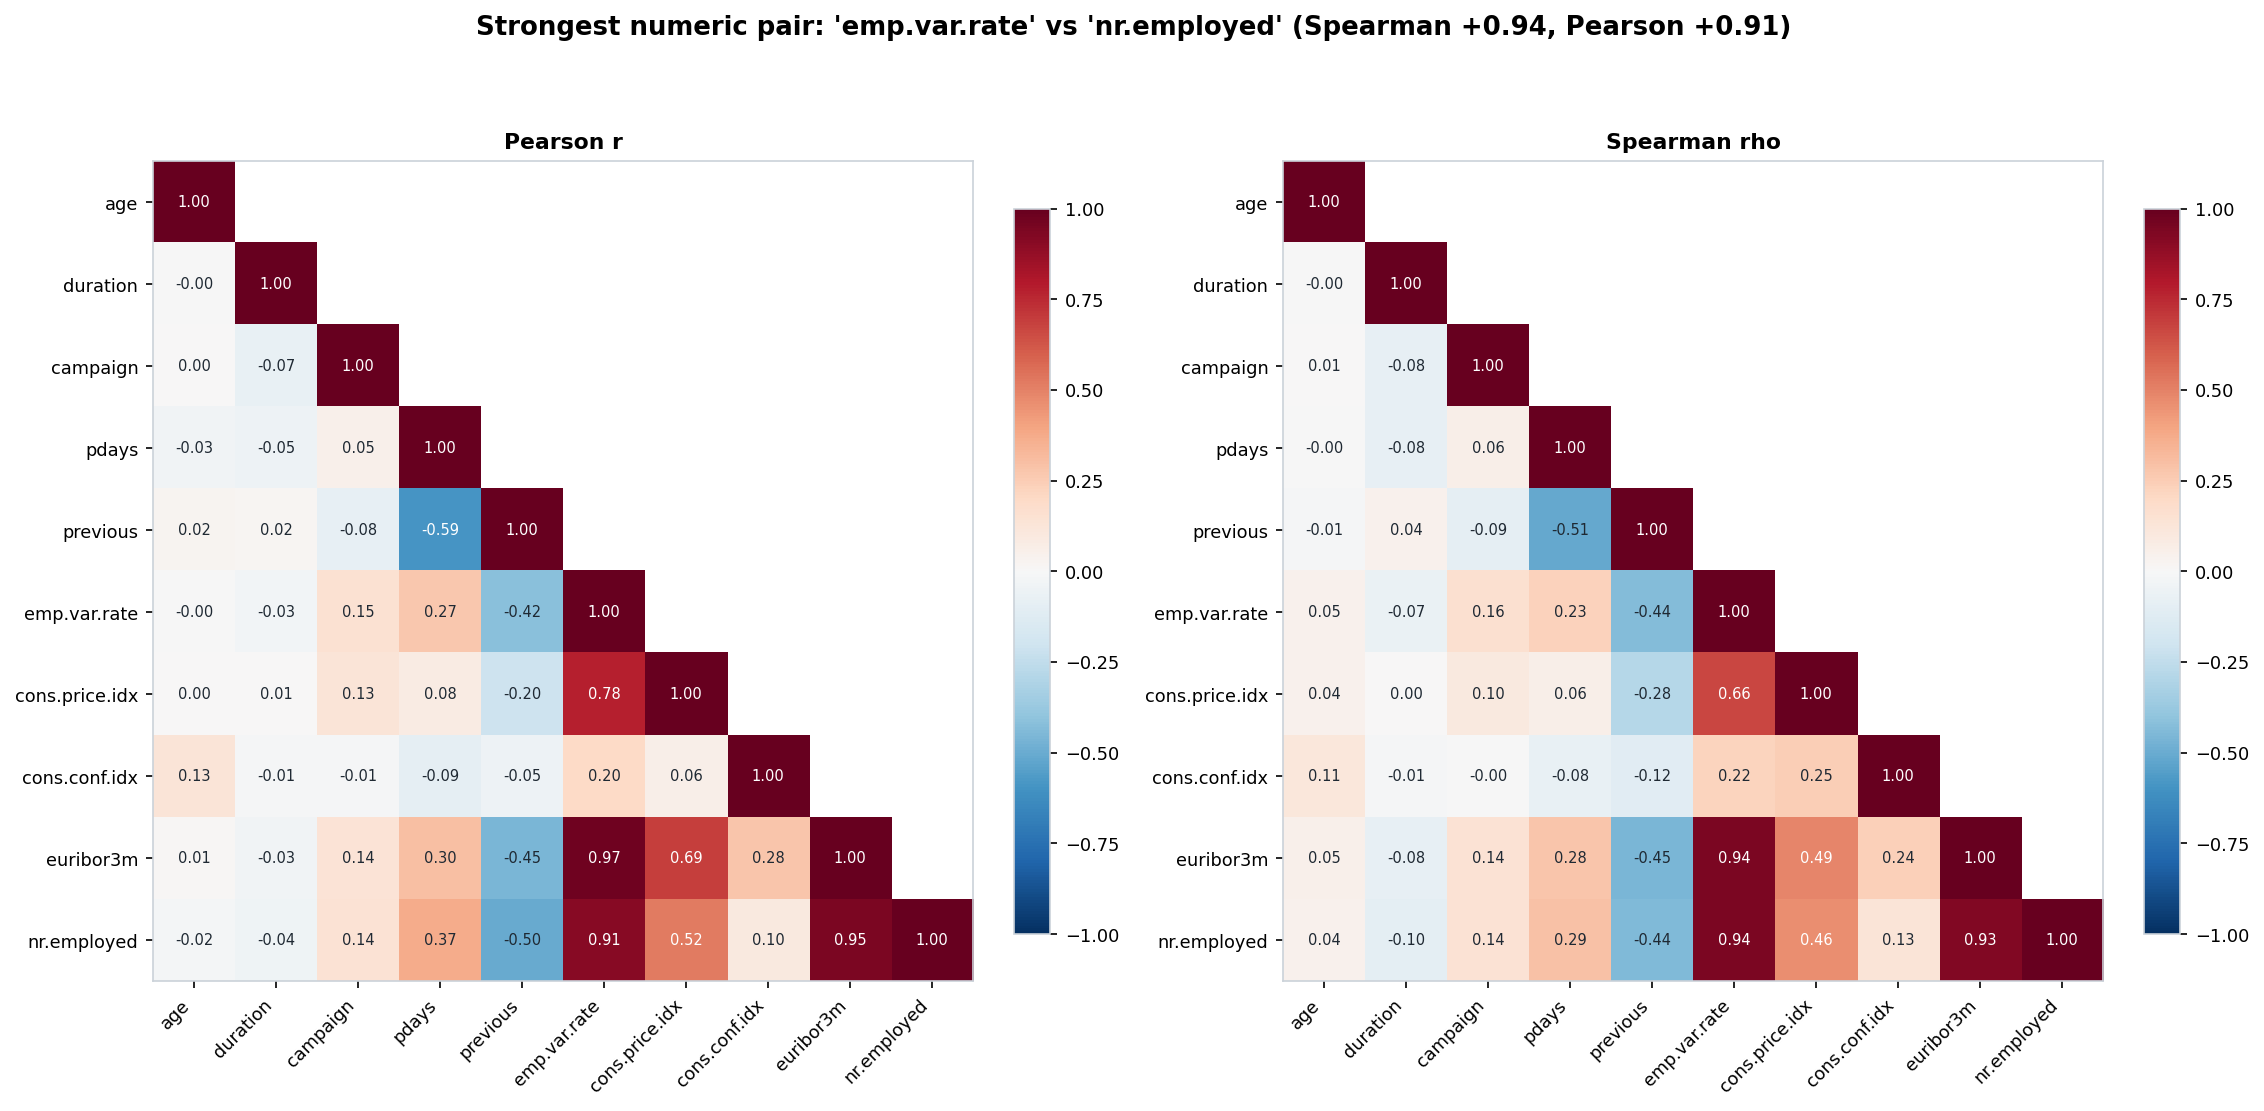

#### Top 6 numeric pairs by |Spearman rho|
*Figure 19. Top 6 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


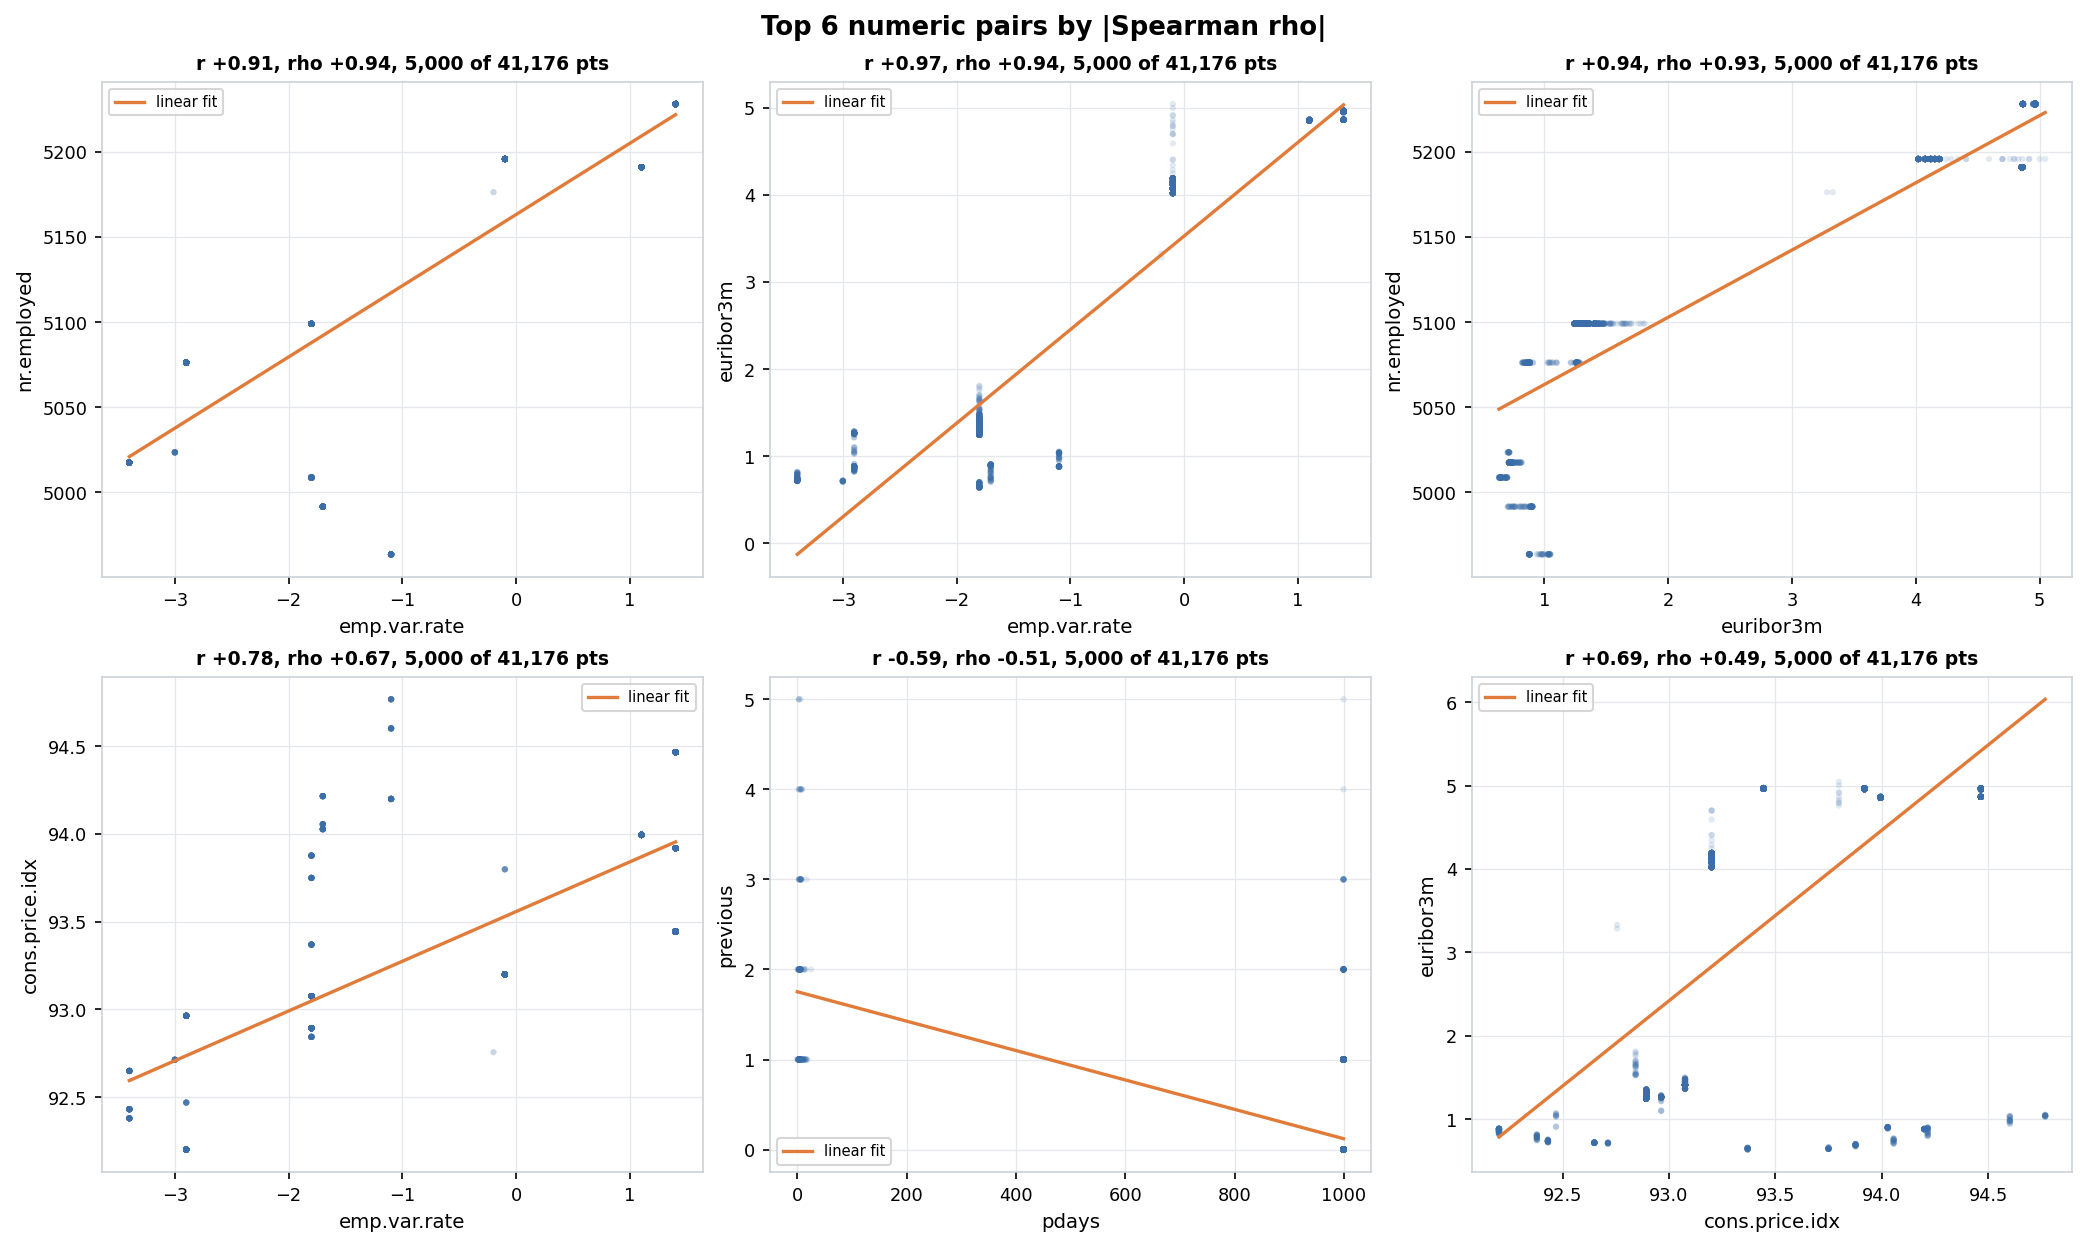

#### 'poutcome' separates 'pdays' the most (eta² 0.91 = share of its spread explained by the groups)
*Figure 20. 'poutcome' separates 'pdays' the most (eta² 0.91 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


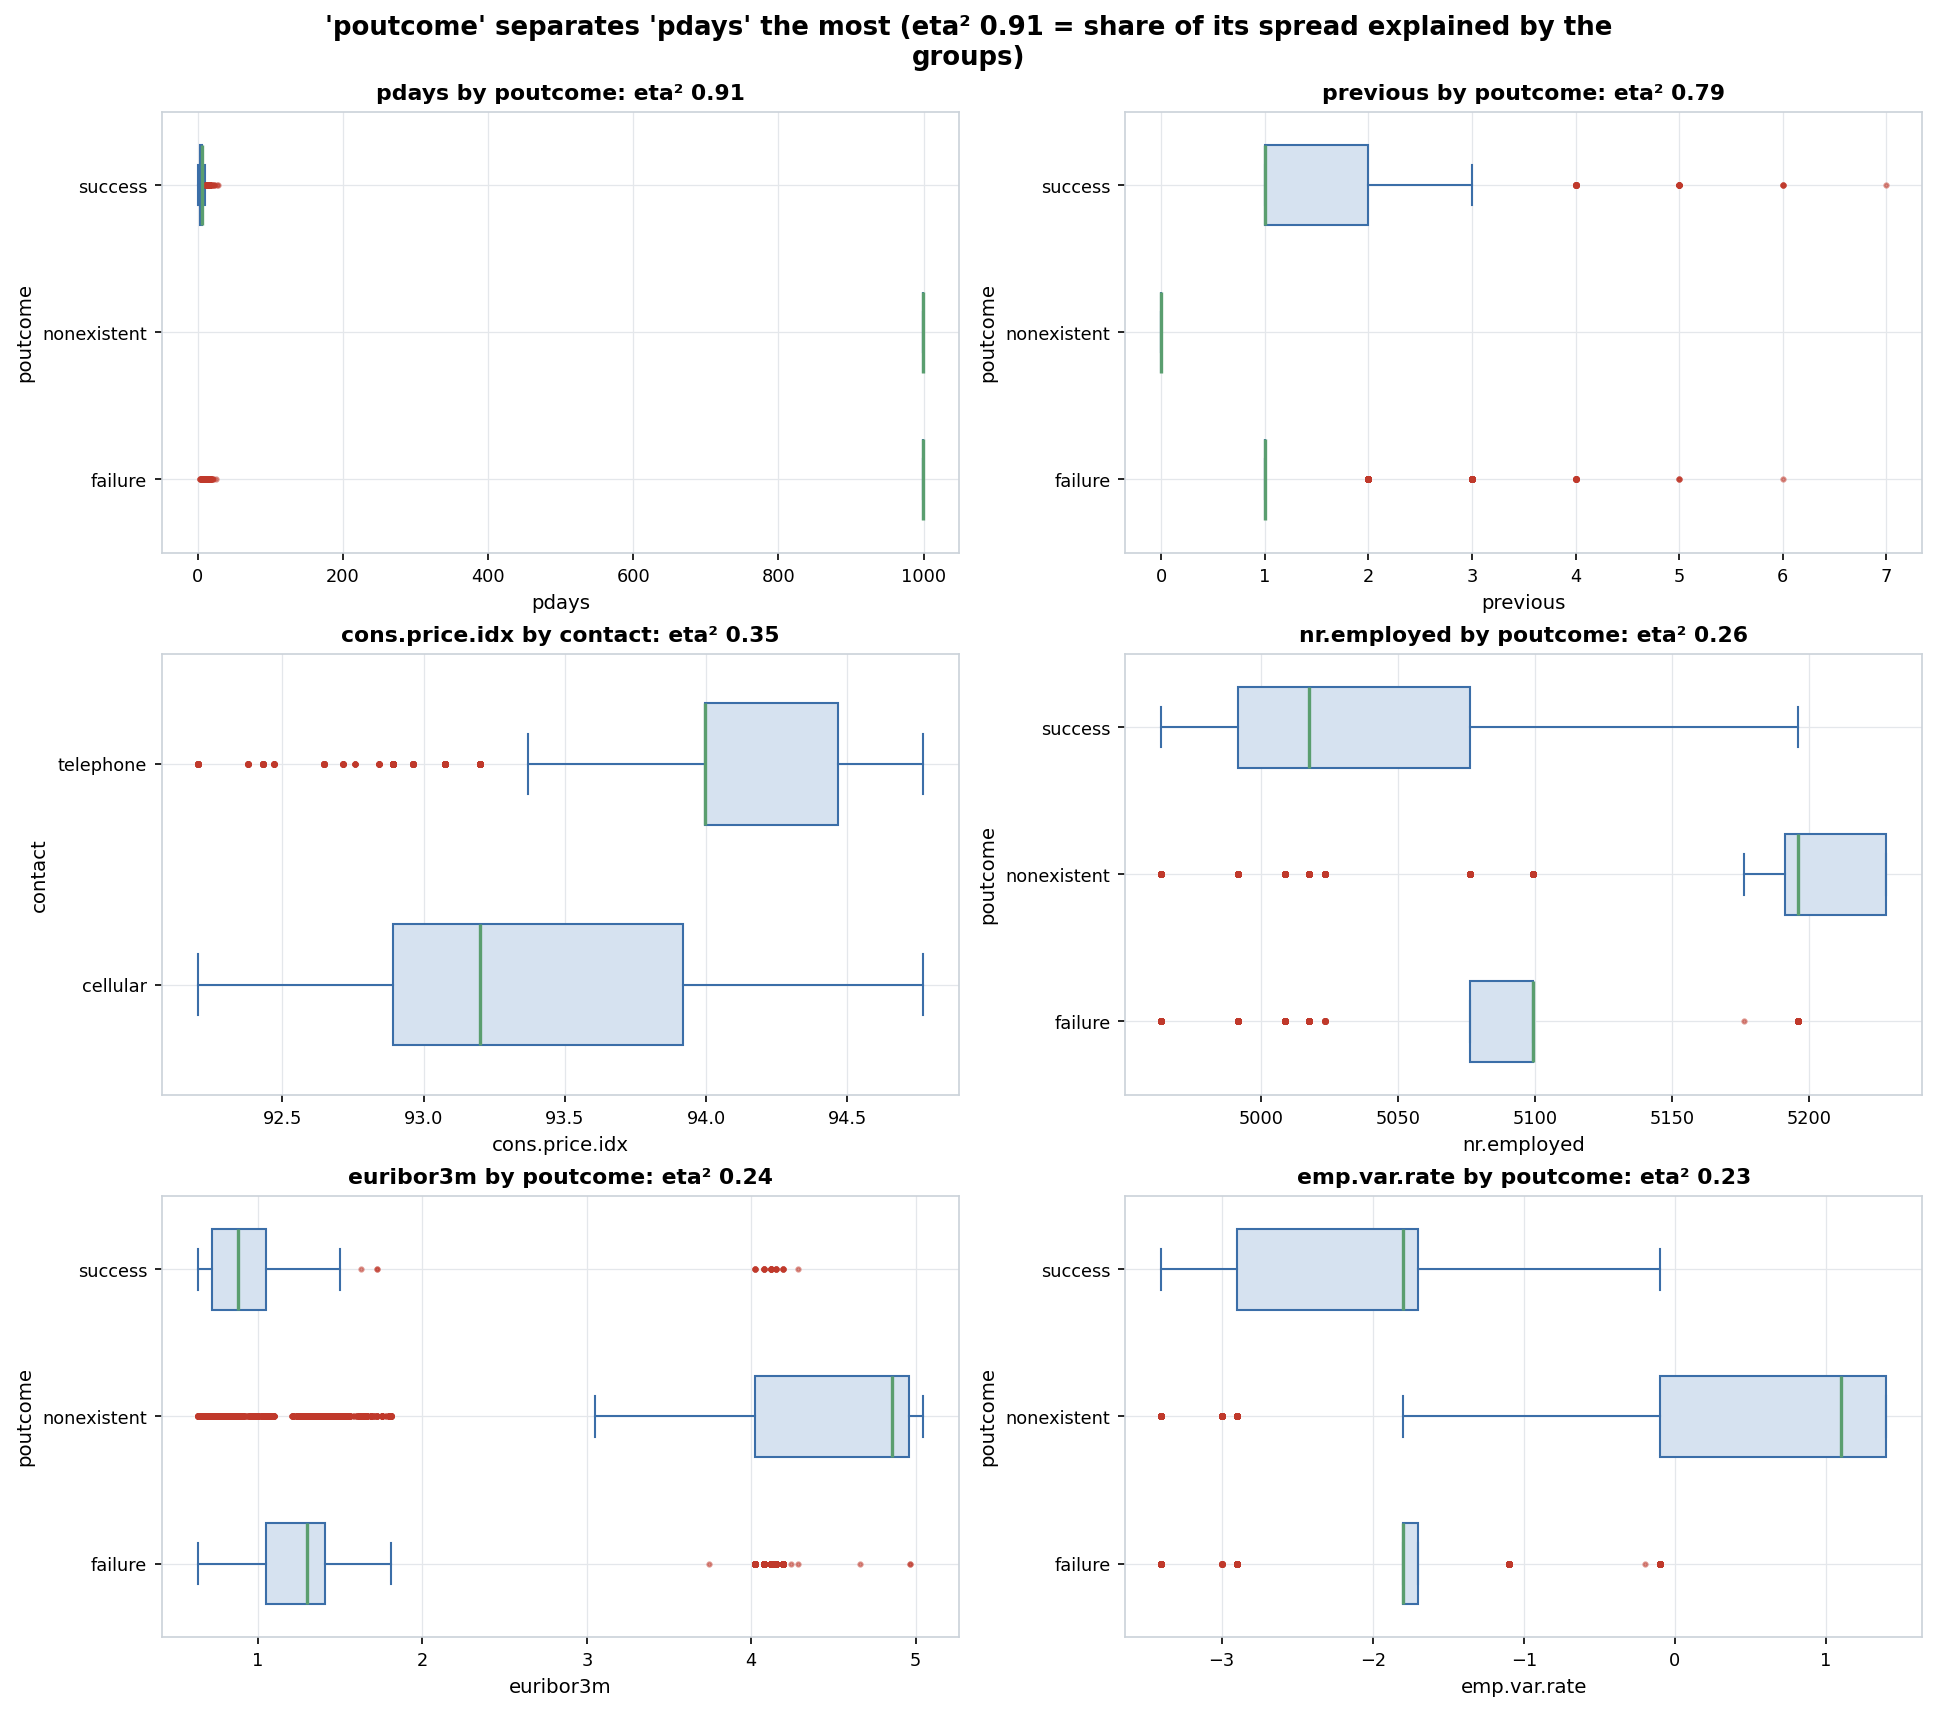

#### Strongest categorical pair: 'contact' vs 'month' (Cramér's V 0.61)
*Figure 21. Strongest categorical pair: 'contact' vs 'month' (Cramér's V 0.61).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


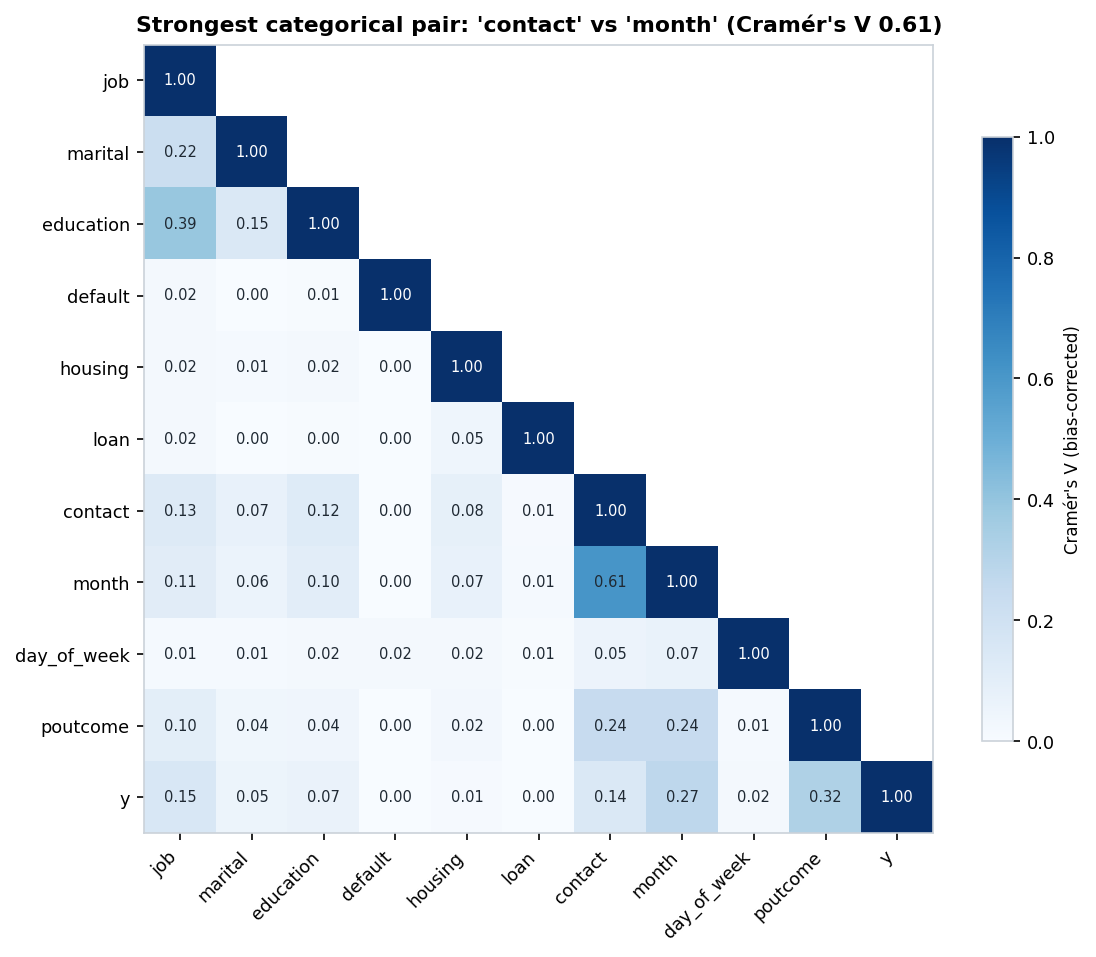

#### Level-by-level mix for the most associated categorical pairs
*Figure 22. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


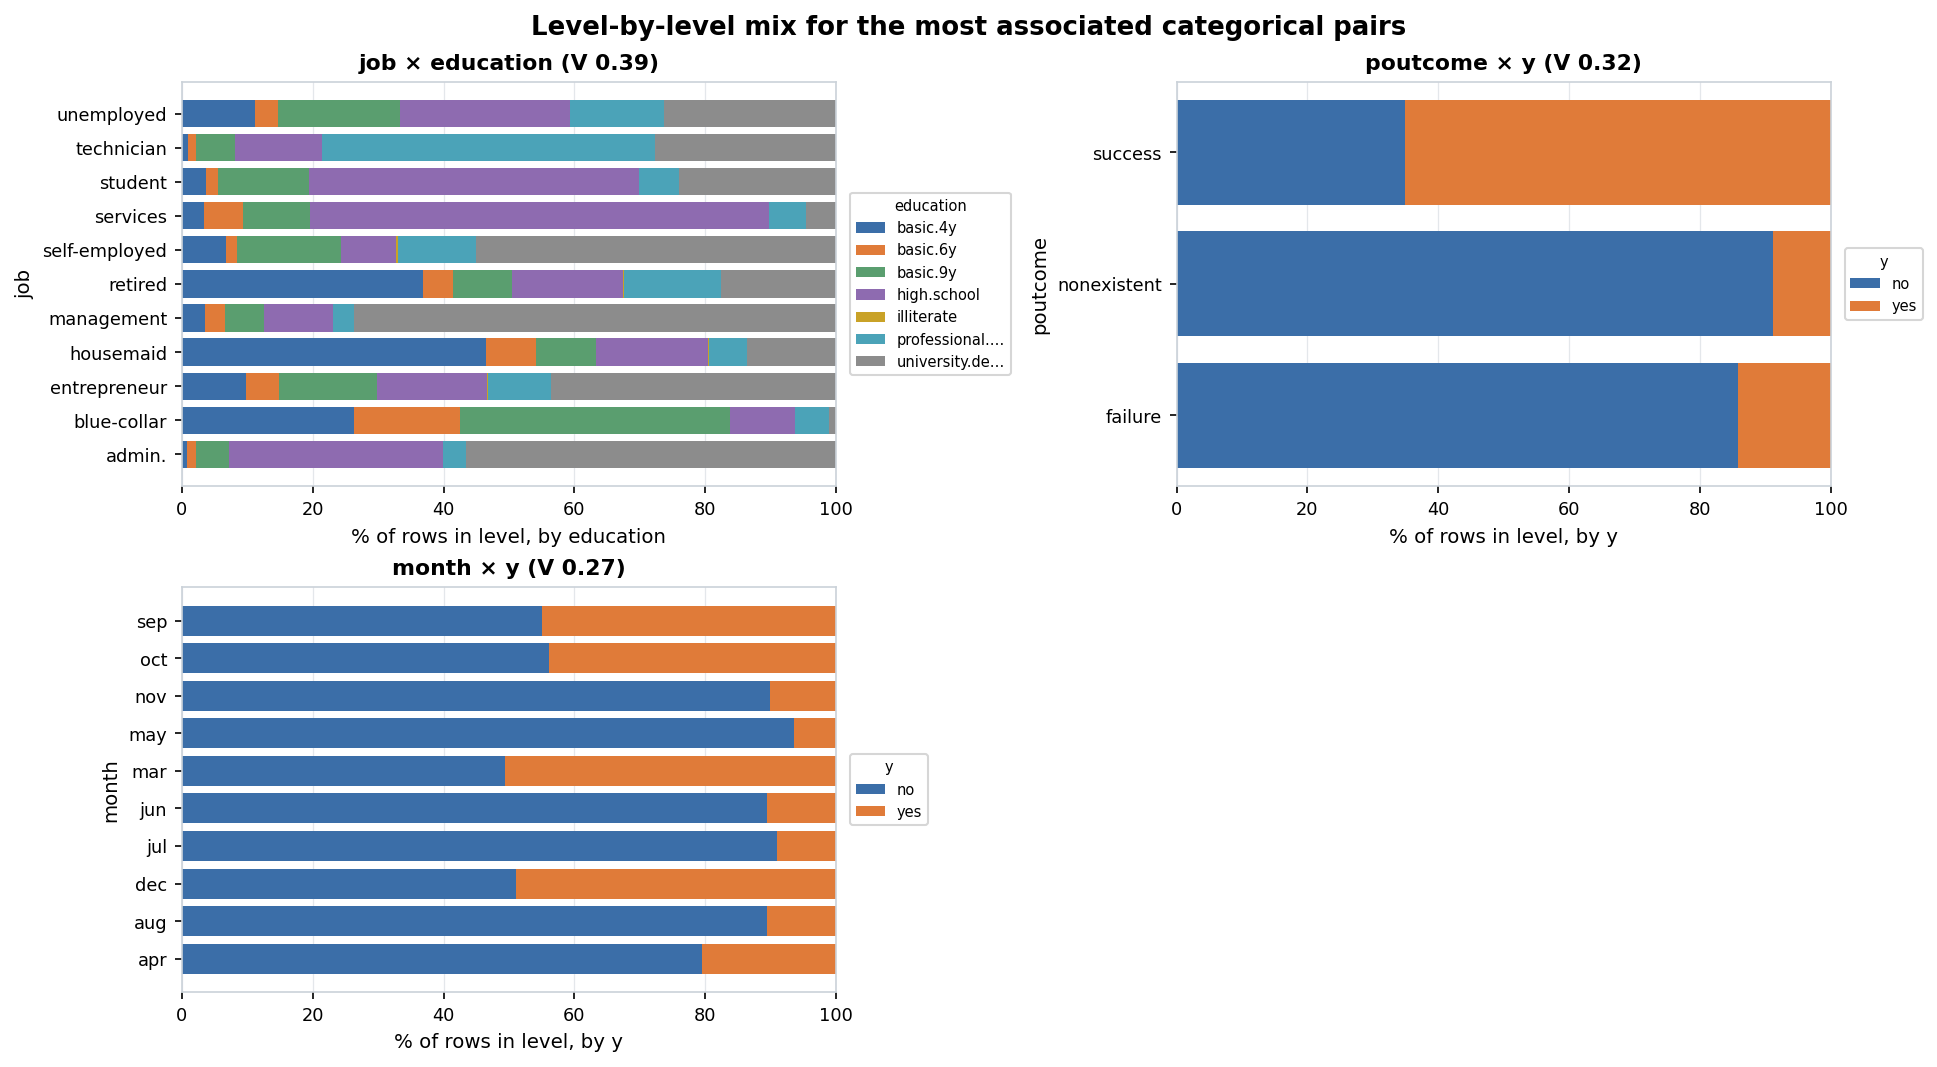

#### 'poutcome' has the strongest association with 'y' (Cramér's V 0.32)
*Figure 23. 'poutcome' has the strongest association with 'y' (Cramér's V 0.32).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


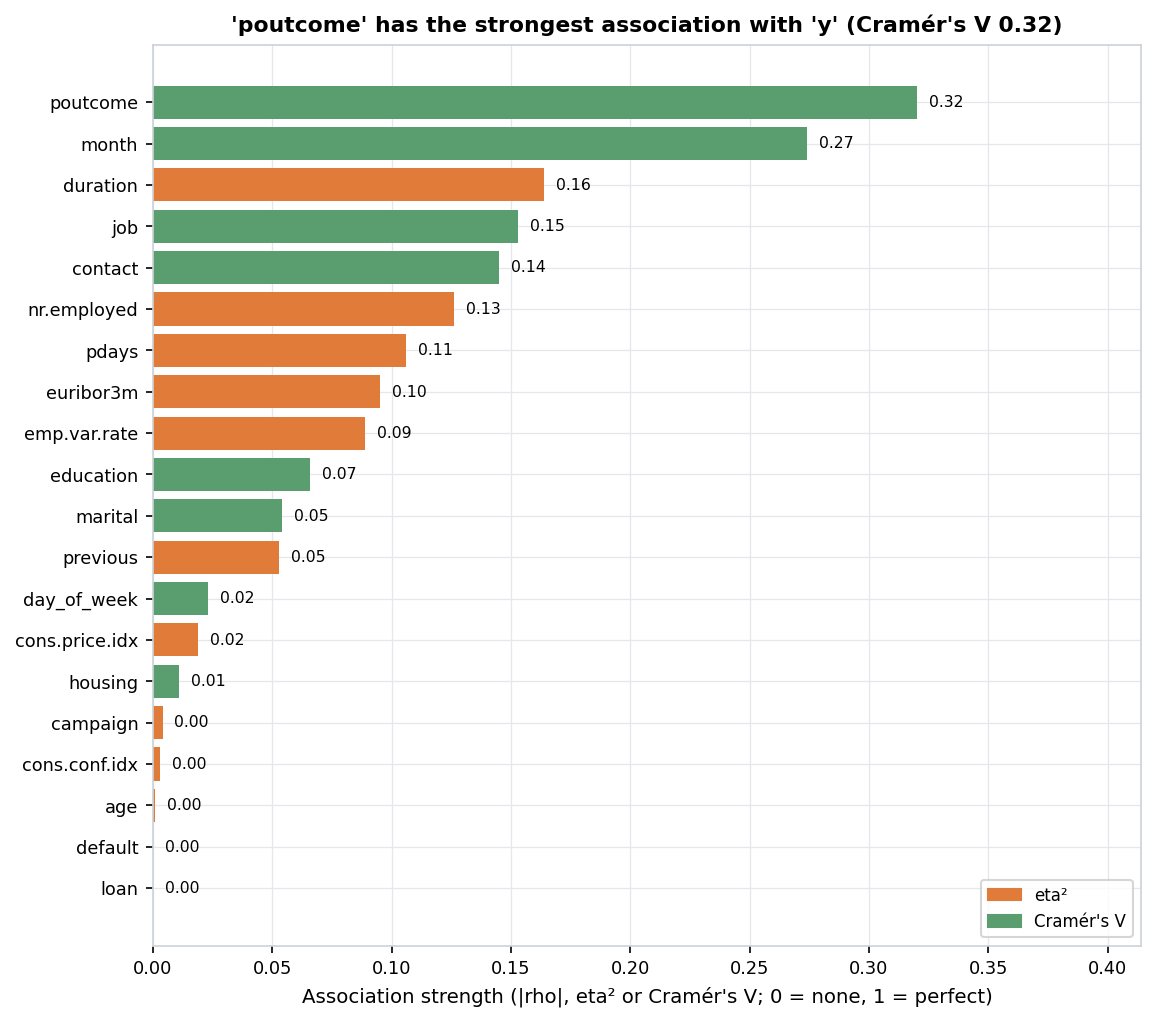

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `bank_marketing`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [duration, campaign, previous] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `259.3053`
- **Min standard deviation:** `0.4950`
- **Scale disparity ratio (`max_std / min_std`):** `523.89x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `age` | 0.785 | 0.791 | 17 | 98 | 10.421 | True | `none` | Moderate/low skewness (skew=0.78); no non-linear transform needed. |
| `duration` | 3.263 | 20.244 | 0 | 4918 | 259.305 | True | `log1p` | Right-skewed (skew=3.26 > 1.0) with non-negative domain (min=0); log1p recommended. |
| `campaign` | 4.762 | 36.972 | 1 | 56 | 2.770 | True | `log1p` | Right-skewed (skew=4.76 > 1.0) with non-negative domain (min=1); log1p recommended. |
| `pdays` | -4.921 | 22.222 | 0 | 999 | 186.937 | True | `none` | Moderate/low skewness (skew=-4.92); no non-linear transform needed. |
| `previous` | 3.831 | 20.102 | 0 | 7 | 0.495 | True | `log1p` | Right-skewed (skew=3.83 > 1.0) with non-negative domain (min=0); log1p recommended. |
| `emp.var.rate` | -0.724 | -1.063 | -3.4 | 1.4 | 1.571 | False | `none` | Moderate/low skewness (skew=-0.72); no non-linear transform needed. |
| `cons.price.idx` | -0.231 | -0.830 | 92.201 | 94.767 | 0.579 | True | `none` | Moderate/low skewness (skew=-0.23); no non-linear transform needed. |
| `cons.conf.idx` | 0.303 | -0.359 | -50.8 | -26.9 | 4.628 | False | `none` | Moderate/low skewness (skew=0.30); no non-linear transform needed. |
| `euribor3m` | -0.709 | -1.407 | 0.634 | 5.045 | 1.734 | True | `none` | Moderate/low skewness (skew=-0.71); no non-linear transform needed. |
| `nr.employed` | -1.044 | -0.004 | 4963.6 | 5228.1 | 72.251 | True | `none` | Moderate/low skewness (skew=-1.04); no non-linear transform needed. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\bank_marketing_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `bank_marketing`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **MEDIUM** — 12 exact duplicate rows were removed (the first copy of each was kept).
- **MEDIUM** — Column 'default' has 20.88% missing values (n = 8,596 of 41,176 rows). ([figure](figures/missing_bar.png))
- **MEDIUM** — Column 'default' used placeholder text for missing values: 'unknown' (8,597); 8,597 cells were turned into real missing values.
- **LOW** — Column 'education' has 4.2% missing values (n = 1,730 of 41,176 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'housing' has 2.4% missing values (n = 990 of 41,176 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'job' has 0.8% missing values (n = 330 of 41,176 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'loan' has 2.4% missing values (n = 990 of 41,176 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'marital' has 0.19% missing values (n = 80 of 41,176 rows). ([figure](figures/missing_bar.png))
- **LOW** — Column 'education' used placeholder text for missing values: 'unknown' (1,731); 1,731 cells were turned into real missing values.
- **LOW** — Column 'housing' used placeholder text for missing values: 'unknown' (990); 990 cells were turned into real missing values.
- **LOW** — Column 'job' used placeholder text for missing values: 'unknown' (330); 330 cells were turned into real missing values.
- **LOW** — Column 'loan' used placeholder text for missing values: 'unknown' (990); 990 cells were turned into real missing values.
- **LOW** — Column 'marital' used placeholder text for missing values: 'unknown' (80); 80 cells were turned into real missing values.

### Distributions

- **MEDIUM** — 'nr.employed' is left-skewed (skew = -1.04): its median (5,191) is above its mean (5,167.03). ([figure](figures/numeric_detail_nr_employed.png))
- **MEDIUM** — 'pdays' is left-skewed (skew = -4.92): its median (999) is above its mean (962.46). ([figure](figures/numeric_detail_pdays.png))
- **MEDIUM** — 'campaign' has many outliers: 5.84% of its values (n = 2,406) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'duration' has many outliers: 7.2% of its values (n = 2,963) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'previous' has many outliers: 13.66% of its values (n = 5,625) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'campaign' is right-skewed (skew = 4.76): its median (2) is below its mean (2.57), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_campaign.png))
- **MEDIUM** — 'duration' is right-skewed (skew = 3.26): its median (180) is below its mean (258.32), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_duration.png))
- **MEDIUM** — 'previous' is right-skewed (skew = 3.83): its median (0) is below its mean (0.17), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_previous.png))
- **MEDIUM** — 'previous' is zero-inflated: 86.34% of its values are exactly zero. ([figure](figures/numeric_detail_previous.png))
- **LOW** — 'cons.conf.idx' may have 3 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_2.png))
- **LOW** — 'cons.price.idx' may have 5 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_2.png))
- **LOW** — 'emp.var.rate' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))
- **LOW** — 'euribor3m' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_2.png))
- **LOW** — 'nr.employed' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_detail_nr_employed.png))

### Class balance

- **MEDIUM** — Target 'y' is mildly imbalanced: the smallest class 'yes' is 11.27% of rows and the largest 'no' is 88.73% (the largest class is 7.88 times the smallest). ([figure](figures/target_balance.png))

### Relationships (descriptive)

- **MEDIUM** — 'emp.var.rate' and 'euribor3m' are nearly collinear (Pearson r = +0.97); models should not use both as if they were separate information. ([figure](figures/correlation_heatmap.png))
- **MEDIUM** — 'emp.var.rate' and 'nr.employed' are nearly collinear (Pearson r = +0.91); models should not use both as if they were separate information. ([figure](figures/correlation_heatmap.png))
- **MEDIUM** — 'euribor3m' and 'nr.employed' are nearly collinear (Pearson r = +0.94); models should not use both as if they were separate information. ([figure](figures/correlation_heatmap.png))
- **MEDIUM** — The categorical feature most associated with target 'y' is 'poutcome' (Cramér's V = 0.32; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — 'contact' and 'month' are associated (bias-corrected Cramér's V = 0.61; descriptive). ([figure](figures/cramers_v_heatmap.png))
- **LOW** — 'job' and 'education' are associated (bias-corrected Cramér's V = 0.39; descriptive). ([figure](figures/cramers_v_heatmap.png))
- **LOW** — Groups of 'poutcome' differ in 'pdays': the groups explain 91% of its variance (eta² = 0.91; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — Groups of 'poutcome' differ in 'previous': the groups explain 79% of its variance (eta² = 0.79; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — 'emp.var.rate' and 'euribor3m' rise together (Spearman rho = +0.94, Pearson r = +0.97; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'emp.var.rate' and 'nr.employed' rise together (Spearman rho = +0.94, Pearson r = +0.91; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'euribor3m' and 'nr.employed' rise together (Spearman rho = +0.93, Pearson r = +0.94; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — The numeric feature most associated with target 'y' is 'duration' (eta² = 0.16; descriptive). ([figure](figures/target_relationships.png))

### Cardinality and structure

- **LOW** — 'default' has 1 level(s) under 1% of rows (e.g. 'yes', n = 3); these will give sparse cells in later chi-square tests (Phase 3). ([figure](figures/categorical_distributions_1.png))
- **LOW** — 'education' has 1 level(s) under 1% of rows (e.g. 'illiterate', n = 18); these will give sparse cells in later chi-square tests (Phase 3). ([figure](figures/categorical_distributions_1.png))
- **LOW** — 'month' has 1 level(s) under 1% of rows (e.g. 'dec', n = 182); these will give sparse cells in later chi-square tests (Phase 3). ([figure](figures/categorical_distributions_2.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 523.89 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.
- **INFO** — Scaling note: log1p is recommended for 'campaign' (skew = 4.76) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'duration' (skew = 3.26) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'previous' (skew = 3.83) for plots and parametric models only; the main cleaned file is not transformed.

### Implications for later testing

- **MEDIUM** — Rank-based methods (Spearman, Mann-Whitney, Kruskal-Wallis) are recommended for 5 skewed or outlier-heavy column(s): 'campaign', 'duration', 'nr.employed', 'pdays', 'previous'.
- **MEDIUM** — Because target 'y' is mildly imbalanced, compare groups using rates (% per class) rather than raw counts, and use stratified splits for any later modeling. ([figure](figures/target_balance.png))
- **LOW** — Group sizes are very unbalanced for 'default': 'no' covers 99.99% of rows and 'yes' only 3 rows, so comparisons across its levels will rest on few cases. ([figure](figures/categorical_distributions_1.png))

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Explicit `"unknown"` missing placeholders across 6 columns:** Rather than blank cells, missing categorical attributes are encoded as `"unknown"` in `default` (8,597 rows, 20.88%), `education` (1,731 rows, 4.20%), `housing` (990 rows, 2.40%), `loan` (990 rows, 2.40%), `job` (330 rows, 0.80%), and `marital` (80 rows, 0.19%). Enabling `treat_unknown_as_missing: true` converts all 12,718 cells to `NaN` in the conservative output and creates `__was_missing` indicator flags in the imputed output.
- **Co-missingness between `housing` and `loan`:** Missingness in `housing` and `loan` is perfectly correlated ($r = 1.00$, exact same 990 rows), indicating that loan-status questions were skipped together as a single survey block.
- **Target leakage in call `duration`:** Call `duration` is the strongest numeric predictor of subscription `y` ($\eta^2 = 0.16$, Spearman $\rho = +0.35$), and `duration == 0` always implies `y = no`. However, call duration is unknown before placing a telemarketing call and must be excluded from realistic predictive models (kept in Phase 1 for retrospective EDA).
- **Sentinel value `pdays = 999`:** 96.32% of clients have `pdays = 999` (meaning "never previously contacted"). Replacing `999` with `NaN` would wipe out 96% of the column; keeping it as a documented sentinel explains its extreme skewness (`skew = -4.92`) and its near-perfect alignment with `poutcome = nonexistent` ($\eta^2 = 0.90$).
- **Near-collinear macroeconomic indicators:** `euribor3m`, `emp.var.rate`, and `nr.employed` move together across the May 2008–Nov 2010 timeline with Pearson $r$ between $+0.94$ and $+0.97$. During periods of lower Euribor rates and reduced employment variation, term-deposit conversion rates (`y = yes`, 11.27% overall) increase substantially.
- **Target findings for Phase 5 benchmark recovery:** (1) `duration <-> y` (strongest post-call association / leakage feature), (2) `poutcome (success) / pdays <-> y` (prior campaign success), (3) `euribor3m / emp.var.rate / nr.employed <-> y` (macroeconomic regime effect), and (4) `contact (cellular vs telephone) <-> y`.
<!-- MANUAL:END -->
